In [31]:
import matplotlib.pyplot as plt
import matplotlib
import numpy as np

from astropy import constants as cst
from astropy import units as u
import healpy as hp

from aqn import *
from constants import *
from survey_parameters import *
from aqn_simulation import *

import sys
sys.path.append('../analysis')

from scipy.fft import fftn, ifftn, fftshift, ifftshift

# Helper functions

## Importing

In [2]:
def import_cubes(location="../data/FIRE/"):
    grid_coords = np.load("../data/FIRE/grid-coords.npy") # !!! these are now rotated!

    cubes = {}
    
    cubes["aqn_emit"] = np.load(location + "cubes/cube-aqn_emit.npy") * u.photon / u.cm**3 / u.s / u.Angstrom / u.sr
    cubes["dark_mat"] = np.load(location + "cubes/cube-dark_mat_density.npy") * u.kg/u.m**3 #* 2/5
    
    cubes["efrac"] = np.load(location + "cubes/cube-gas_efrac.npy")

    cubes["temp_ion"] = np.load(location + "cubes/cube-gas_temp.npy") * u.K * K_to_eV
    
    cubes["gas"] = np.load(location + "cubes/cube-gas_density.npy") * u.kg/u.m**3
    cubes["gas"] = (cubes["gas"]/cst.m_p.si).to(1/u.cm**3)
    
    cubes["dv"] = np.load(location + "cubes/cube-dv.npy") / 1000 * u.km/u.s
    
    cubes["ioni_gas"], cubes["neut_gas"] = compute_ioni_neut_gas(cubes["gas"], cubes["efrac"])
    
    return grid_coords, cubes

In [3]:
def generate_cylinder_filters(n):
    # Define radii
    s_inner = 7.8
    s_outer = 9.2
    
    # Angular range for each slice
    delta_theta = 2 * np.pi / n
    
    filters = []
    
    for i in range(n):
        theta_min = i * delta_theta
        theta_max = (i + 1) * delta_theta
        filters.append(np.where((s[within_cylinder] >= s_inner) & (s[within_cylinder] <= s_outer) & 
                                (theta[within_cylinder] >= theta_min) & (theta[within_cylinder] < theta_max) & 
                                (np.abs(z[within_cylinder]) < 1.2)))
    return filters

In [4]:
def fix_grid_coords_rotation(grid_coords):

    # these are the correct ones from the binned histogram notebook
    
    ############### Rotation 1 ####################
    theta = np.radians(11)  # Convert angle to radians
    cos_theta, sin_theta = np.cos(theta), np.sin(theta)
    rotation_matrix = np.array([
        [1, 0, 0],
        [0, cos_theta, -sin_theta],
        [0, sin_theta, cos_theta]
    ])
    
    grid_coords = grid_coords @ rotation_matrix.T
    ###############################################
    
    ############### Rotation 2 ####################
    theta = np.radians(30)  # Convert angle to radians
    cos_theta, sin_theta = np.cos(theta), np.sin(theta)
    rotation_matrix = np.array([
        [cos_theta, 0, -sin_theta],
        [0, 1, 0],
        [sin_theta, 0, cos_theta]
    ])
    
    grid_coords = grid_coords @ rotation_matrix.T
    ###############################################

    return grid_coords

In [5]:
def fix_grid_coords_rotation(grid_coords):
    ############### Rotation 1 ####################
    theta = np.radians(30)  # Convert angle to radians
    cos_theta, sin_theta = np.cos(theta), np.sin(theta)
    rotation_matrix = np.array([
        [1, 0, 0],
        [0, cos_theta, -sin_theta],
        [0, sin_theta, cos_theta]
    ])
    
    grid_coords = grid_coords @ rotation_matrix.T
    ###############################################
    ############### Rotation 2 ####################
    theta = np.radians(11)  # Convert angle to radians
    cos_theta, sin_theta = np.cos(theta), np.sin(theta)
    rotation_matrix = np.array([
        [cos_theta, 0, -sin_theta],
        [0, 1, 0],
        [sin_theta, 0, cos_theta]
    ])
    
    grid_coords = grid_coords @ rotation_matrix.T
    ###############################################

    return grid_coords

## Plotting

In [6]:
def plot_demo_cylinder_filters():
    plt.figure(figsize=(10,10), dpi=50)
    for i in range(2):
        plt.scatter(x[within_cylinder][filters[i]], y[within_cylinder][filters[i]], label=str(i))
    plt.legend()
    plt.show()

In [7]:
def plot_cube_2(ax, quant, grid_coords):
    z_min, z_max = -2, 2
    grid_size = 100
    
    # Filter particles within the z range
    z_coords = grid_coords[:, 2]
    z_mask = (z_coords >= z_min) & (z_coords <= z_max)
    
    # Select the particles and densities within this range
    filtered_coords = grid_coords[z_mask]
    
    filtered_densities = np.reshape(quant, (512**3))[z_mask].value
    
    # Project onto the x-y plane
    x_coords = filtered_coords[:, 0]
    y_coords = filtered_coords[:, 1]
    
    # Create a 2D histogram to count the number of points in each bin (density map)
    count_hist, xedges, yedges = np.histogram2d(x_coords, y_coords, bins=grid_size)
    
    # Create a 2D histogram weighted by the densities
    weighted_hist, _, _ = np.histogram2d(x_coords, y_coords, bins=grid_size, weights=filtered_densities)
    
    # Normalize by the number of points in each bin to get the average density
    with np.errstate(divide='ignore', invalid='ignore'):  # Handle division by zero
        normalized_hist = np.divide(weighted_hist, count_hist)
        normalized_hist[np.isnan(normalized_hist)] = 0  # Replace NaNs with zeros (where there are no points)
    
    # Plot the normalized 2D histogram
    ax.imshow(normalized_hist.T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]])
    # ax.set_colorbar(label='')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_title('Projection in X-Y Plane, Z ∈ [-2,2] kpc')


In [8]:
def plot_slice_outlines(ax, n, title):
    r_outer = 9.4
    r_inner = 7.0
    
    colors_list = [plt.cm.ocean(i / n) for i in range(16)]
    
    ax.set_title(title)
    ax.set_aspect('equal', 'box')  # Keep the aspect ratio square
    ax.set_xlim(-r_outer-1, r_outer+1)
    ax.set_ylim(-r_outer-1, r_outer+1)
    
    # Plot each slice's outline
    for i in range(n):
        # Angular range for this slice
        th_min = i * 2 * np.pi / n
        th_max = (i + 1) * 2 * np.pi / n
        
        # Generate the points for the outer and inner arcs
        th = np.linspace(th_min, th_max, 100)
        x_outer = r_outer * np.cos(th)
        y_outer = r_outer * np.sin(th)
        x_inner = r_inner * np.cos(th)
        y_inner = r_inner * np.sin(th)
        
        # Plot the outer and inner arcs
        ax.plot(x_outer, y_outer, color=colors_list[i], lw=2)
        ax.plot(x_inner, y_inner, color=colors_list[i], lw=2)
        
        # Optionally, connect the outer and inner arcs to form the slice boundary
        ax.plot([x_outer[0], x_inner[0]], [y_outer[0], y_inner[0]], color=colors_list[i], lw=2)
        ax.plot([x_outer[-1], x_inner[-1]], [y_outer[-1], y_inner[-1]], color=colors_list[i], lw=2)

In [9]:
def visualize_sum_along_axis(array, axis, index_range, title):
    """
    Visualize a sum of pixels along a given axis of a 3D array between two indices.

    :param array: 3D numpy array.
    :param axis: The axis along which to sum (0, 1, or 2).
    :param index_range: Tuple (start_index, end_index) for the range of indices along the given axis.
    :param title: Title of the plot.
    """
    start_idx, end_idx = index_range

    # Sum along the chosen axis in the given index range
    summed_array = np.sum(array.take(indices=range(start_idx, end_idx), axis=axis), axis=axis)

    # Plot the result
    plt.imshow(summed_array, cmap='gray')
    plt.title(f'{title} (Σ index {start_idx}-{end_idx} along axis {axis})')
    plt.colorbar()
    plt.show()

In [10]:
def visualize_sum_along_axis_2(quant, grid_coords, save_name, color_range=False):
    z_min, z_max = -2, 2
    grid_size = 100
    
    # Filter particles within the z range
    z_coords = grid_coords[:, 2]
    z_mask = (z_coords >= z_min) & (z_coords <= z_max)
    
    # Select the particles and densities within this range
    filtered_coords = grid_coords[z_mask]
    
    filtered_densities = np.reshape(quant, (512**3))[z_mask].value
    
    # Project onto the x-y plane
    x_coords = filtered_coords[:, 0]
    y_coords = filtered_coords[:, 1]
    
    # Create a 2D histogram to count the number of points in each bin (density map)
    count_hist, xedges, yedges = np.histogram2d(x_coords, y_coords, bins=grid_size)
    
    # Create a 2D histogram weighted by the densities
    weighted_hist, _, _ = np.histogram2d(x_coords, y_coords, bins=grid_size, weights=filtered_densities)
    
    # Normalize by the number of points in each bin to get the average density
    with np.errstate(divide='ignore', invalid='ignore'):  # Handle division by zero
        normalized_hist = np.divide(weighted_hist, count_hist)
        normalized_hist[np.isnan(normalized_hist)] = 0  # Replace NaNs with zeros (where there are no points)
    print(np.min(normalized_hist), np.max(normalized_hist))
    # Plot the normalized 2D histogram
    if color_range:
        plt.imshow(normalized_hist.T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]], 
                   vmin=color_range[0], vmax=color_range[1]) # Blues or YlOrRd # cmap="YlOrRd"
    else:
        plt.imshow(normalized_hist.T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]])        
    # ax.set_colorbar(label='')
    plt.colorbar()
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Projection in X-Y Plane, Z ∈ [-2,2] kpc')
    plt.savefig("../visuals/"+save_name, bbox_inches = "tight")
    plt.show()

In [11]:
def visualize_sum_along_axis_2(quant, grid_coords, save_name, color_range=False):
    z_min, z_max = -2, 2
    grid_size = 100
    
    # Filter particles within the z range
    z_coords = grid_coords[:, 2]
    z_mask = (z_coords >= z_min) & (z_coords <= z_max)
    
    # Select the particles and densities within this range
    filtered_coords = grid_coords[z_mask]
    
    filtered_densities = np.reshape(quant, (512**3))[z_mask].value
    
    # Project onto the x-y plane
    x_coords = filtered_coords[:, 0]
    y_coords = filtered_coords[:, 1]
    
    # Create a 2D histogram to count the number of points in each bin (density map)
    count_hist, xedges, yedges = np.histogram2d(x_coords, y_coords, bins=grid_size)
    
    # Create a 2D histogram weighted by the densities
    weighted_hist, _, _ = np.histogram2d(x_coords, y_coords, bins=grid_size, weights=filtered_densities)
    
    # Normalize by the number of points in each bin to get the average density
    with np.errstate(divide='ignore', invalid='ignore'):  # Handle division by zero
        normalized_hist = np.divide(weighted_hist, count_hist)
        normalized_hist[np.isnan(normalized_hist)] = 0  # Replace NaNs with zeros (where there are no points)
    print(np.min(normalized_hist), np.max(normalized_hist))
    # Plot the normalized 2D histogram
    if color_range:
        plt.imshow(normalized_hist.T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]], 
                   vmin=color_range[0], vmax=color_range[1]) # Blues or YlOrRd # cmap="YlOrRd"
    else:
        plt.imshow(normalized_hist.T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]])        
    # ax.set_colorbar(label='')
    plt.colorbar()
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Projection in X-Y Plane, Z ∈ [-2,2] kpc')
    plt.savefig("../visuals/"+save_name+".pdf", bbox_inches = "tight")
    plt.show()

from matplotlib import gridspec
def plot_pre_post_convolution(x_pre, x_post, grid_coords, unit_label, save_name, vmin, vmax):
    z_min, z_max = -1,1
    grid_size = 100

    # Filter particles within the z range
    z_coords = grid_coords[:, 2]
    z_mask = (z_coords >= z_min) & (z_coords <= z_max)

    # Select the particles and densities within this range
    filtered_coords = grid_coords[z_mask]

    # Project onto the x-y plane
    x_coords = filtered_coords[:, 0]
    y_coords = filtered_coords[:, 1]

    # Create a 2D histogram to count the number of points in each bin (density map)
    count_hist, xedges, yedges = np.histogram2d(x_coords, y_coords, bins=grid_size)
    
    filtered_densities_pre  = np.reshape(x_pre,  (512**3))[z_mask].value
    filtered_densities_post = np.reshape(x_post, (512**3))[z_mask].value
    
    # Create a 2D histogram weighted by the densities
    weighted_hist_pre, _, _ = np.histogram2d(x_coords, y_coords, bins=grid_size, weights=filtered_densities_pre)
    weighted_hist_post, _, _ = np.histogram2d(x_coords, y_coords, bins=grid_size, weights=filtered_densities_post)

    # Normalize by the number of points in each bin to get the average density
    with np.errstate(divide='ignore', invalid='ignore'):  # Handle division by zero
        normalized_hist_pre  = np.divide(weighted_hist_pre, count_hist)
        normalized_hist_post = np.divide(weighted_hist_post, count_hist)
        normalized_hist_pre[np.isnan(normalized_hist_pre)]   = 0  # Replace NaNs with zeros (where there are no points)
        normalized_hist_post[np.isnan(normalized_hist_post)] = 0
    print(np.min(normalized_hist_pre),  np.max(normalized_hist_pre))
    print(np.min(normalized_hist_post), np.max(normalized_hist_post))
    
    fig = plt.figure(figsize=(12, 6), dpi=500)
    gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1, 0.07])  # Allocate space for colorbar
    ax1 = plt.subplot(gs[0])      # First subplot
    ax2 = plt.subplot(gs[1])      # Second subplot
    cbar_ax = plt.subplot(gs[2])  # Colorbar axis
    
    im1 = ax1.imshow(normalized_hist_pre.T,  extent=[-10, 10, -10, 10], vmin=vmin,vmax=vmax)
    im2 = ax2.imshow(normalized_hist_post.T, extent=[-10, 10, -10, 10], vmin=vmin,vmax=vmax)

        # plt.imshow(normalized_hist.T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]], 
        #            vmin=color_range[0], vmax=color_range[1]) # Blues or YlOrRd # cmap="YlOrRd"
    
    # Add a single colorbar for the second plot
    cbar = fig.colorbar(im2, cax=cbar_ax)
    cbar.ax.tick_params(labelsize=20)
    cbar.set_label(unit_label, fontsize=20)
    
    for ax in [ax1, ax2]:
        # ax.set_xlabel('$x$ [kpc]', size=20)
        ax.set_xticks(np.array([-10,-5,0,5,10]))
        ax.tick_params(labelsize=20)
        ax.set_yticks(np.array([-10,-5,0,5,10]))
    ax1.set_ylabel('$y$ [kpc]', size=24)
    ax1.set_title("Pre-convolution", size=28)
    ax2.set_title("Post-convolution", size=28)
    # ax1.grid()
    # ax2.grid()
    ax2.set_yticklabels([])
    # plt.xlabel('$x$ [kpc]', size=20)
    fig.text(1/2.1, 0.05, '$x$ [kpc]', ha='center', va='center', fontsize=24)
    plt.savefig("../visuals/"+save_name + ".pdf", bbox_inches='tight')
    plt.show()

## Smoothing Kernel & Convolution

In [12]:
def create_kernel(shape):
    """
    Create a 3D kernel with a given shape. 
    In this example, we are creating a simple Gaussian kernel.
    
    :param shape: tuple of 3 integers (x, y, z), specifying the shape of the kernel.
    :return: 3D numpy array representing the kernel.
    """
    x, y, z = np.indices(shape)
    center = np.array(shape) // 2
    sigma = min(shape) / 50.0  # Example: a standard deviation for Gaussian kernel
    print('sigma = ',sigma)

    # Gaussian kernel formula
    kernel = np.exp(-((x - center[0]) ** 2 + (y - center[1]) ** 2 + (z - center[2]) ** 2) / (2 * sigma ** 2))
    
    # Normalize the kernel so that the sum is 1
    return kernel

def spherical_kernel(r, radius):
    """
    Create a 3D spherical averaging kernel based on physical distances (kpc).
    
    :param x, y, z: 3D arrays of coordinates in kpc.
    :param radius: Radius of the sphere in kpc.
    :return: 3D kernel normalized to sum to 1 (averaging kernel).
    """
    # Compute the distance from the center in kpc
    # dist = np.sqrt((x - center[0])**2 + (y - center[1])**2 + (z - center[2])**2)
    
    # Create a binary mask for points inside the sphere
    kernel = (r <= radius).astype(float)
    
    # Normalize to make it an averaging kernel
    kernel /= np.sum(kernel)  # Ensures it computes mean values
    return kernel

def fft_convolve3d_aligned(array, kernel):
    """
    Perform a 3D convolution using FFT, ensuring that the (0,0,0) point of the 
    original array and the convolved result align.
    
    :param array: 3D numpy array representing the input data.
    :param kernel: 3D numpy array representing the kernel to convolve with.
    :return: The result of the convolution with aligned origin (0,0,0).
    """
    # Get the shape of the input array and the kernel
    array_shape = array.shape
    kernel_shape = kernel.shape
    
    # Perform FFT on both the input array and the kernel
    fft_array = fftn(array)
    
    # Shift the kernel so that its center aligns with (0,0,0) in frequency space
    fft_kernel = fftn(ifftshift(kernel), s=array_shape) # !!! why

    # Multiply in frequency domain and take inverse FFT to get the result
    convolved = ifftn(fft_array * fft_kernel)
    
    # Return the real part of the result to discard small imaginary parts
    return np.real(convolved)

# Import cubes and perform initial filtering

### Import cubes

In [13]:
# define cube resolution parameters
cube_length       = 20   # kpc # 20 for radio
voxel_resolution  = 2**9 # bins / 20 kpc
# print(cube_length / voxel_resolution) # kpc voxel length

In [14]:
location = "../data/FIRE/jan9/"
grid_coords, cubes = import_cubes(location)

In [15]:
cubes["s"], cubes["x"],cubes["y"], cubes["z"] = np.sqrt(grid_coords[:,0]**2 + grid_coords[:,1]**2), grid_coords[:,0], grid_coords[:,1], grid_coords[:,2]
r = np.sqrt(grid_coords[:,0]**2 + grid_coords[:,1]**2 + grid_coords[:,2]**2)


In [16]:
r = r.reshape((voxel_resolution, voxel_resolution, voxel_resolution))

### Create smoothing Kernel

0.0 1.9101900897272898e-05


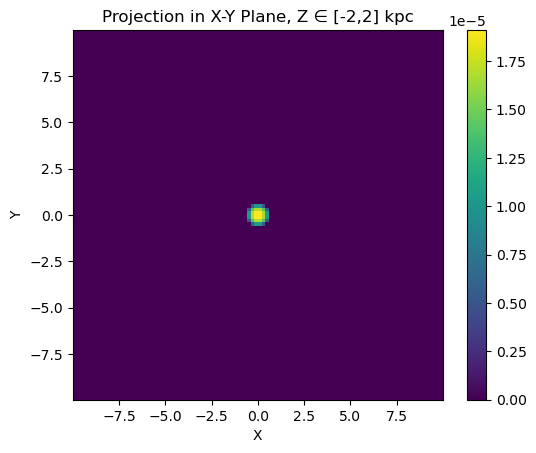

In [17]:
kernel = spherical_kernel(r, 0.6) * u.cm

visualize_sum_along_axis_2(kernel, grid_coords, "kernel_1_6_kpc.png")

In [18]:
cubes["ioni_gas_avg"] = fft_convolve3d_aligned(cubes["ioni_gas"], kernel) * 1/u.cm**3

In [19]:
r = np.sqrt(grid_coords[:,0]**2 + grid_coords[:,1]**2 + grid_coords[:,2]**2)

2.8015961644953503e-05 0.09469833225097571
0.0010854159878671554 0.05981732759341203


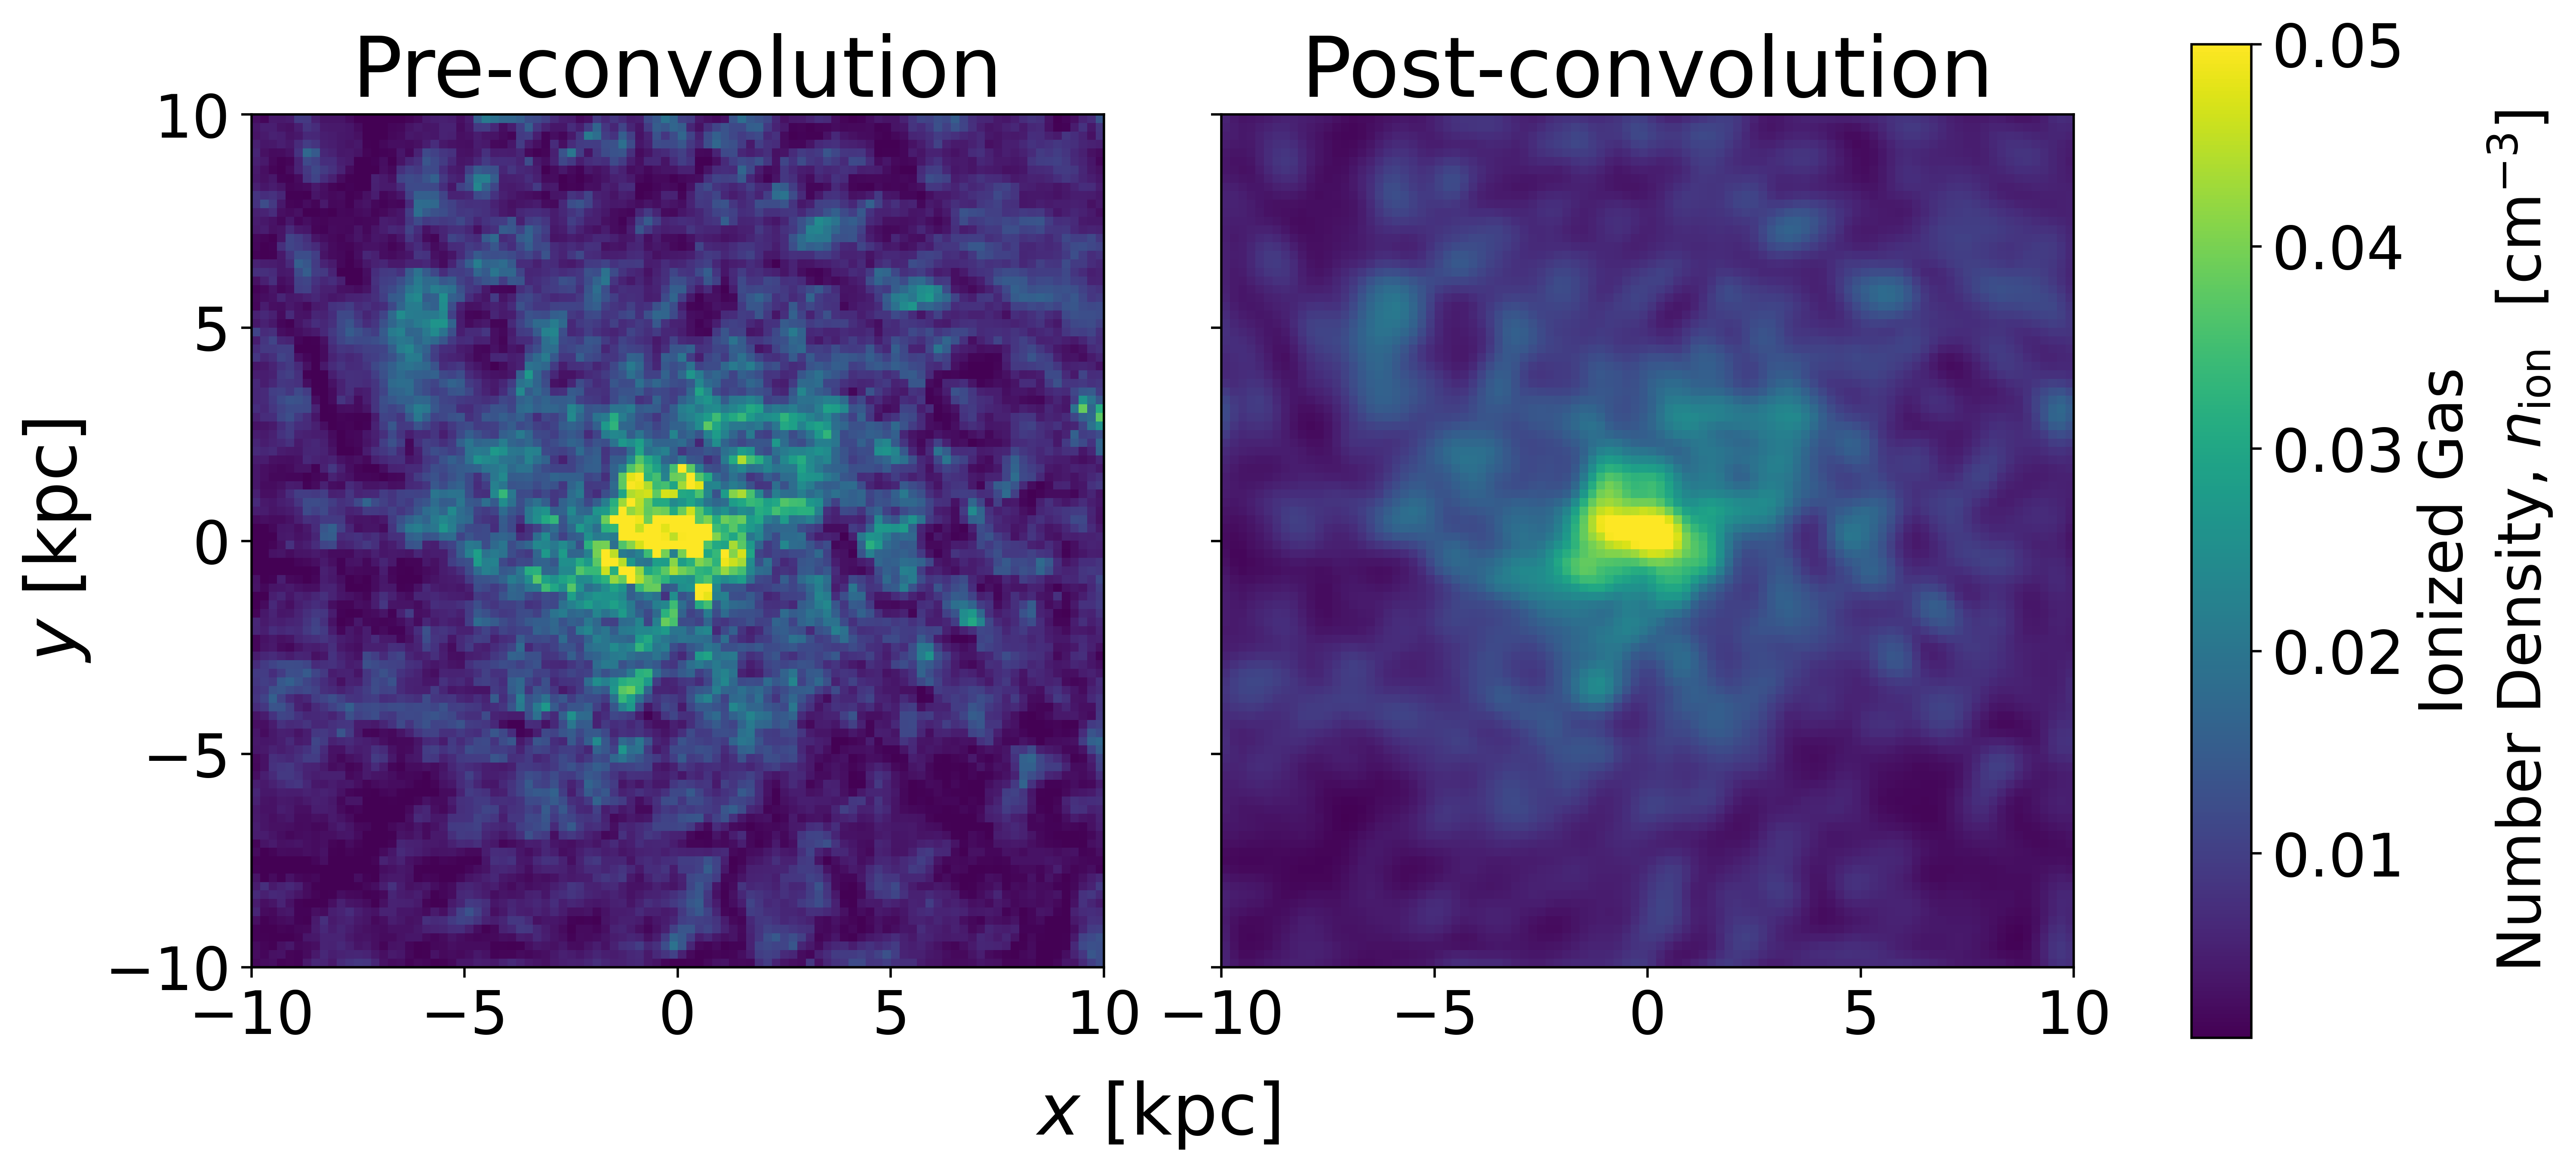

In [20]:
plot_pre_post_convolution(cubes["ioni_gas"], cubes["ioni_gas_avg"], grid_coords, 
                          'Ionized Gas\nNumber Density, '+r'$n_\text{ion}$  [cm$^{-3}$]', "ioni_gas_pre_post_convolution_0_6_kpc_Xe", 0.0009, 0.05)
# visualize_sum_along_axis_2(cubes["ioni_gas_avg"], grid_coords, "ioni_gas_convolution_0_6_kpc_Xe.png", [0.00069,0.0579])
# visualize_sum_along_axis_2(cubes["ioni_gas"], grid_coords, "ioni_gas_no_convolution_Xe.png", [0.00069,0.0579])

## Filter solar region candidates w/o ioni_gas

In [21]:
# Reshape into 1-D to make filtering easier
for quant in cubes:
    cubes[quant] = np.reshape(cubes[quant], voxel_resolution**3)

In [22]:
# new literature values
lit = {}
lit["dark_mat"]   = ((0.42 * u.GeV/u.cm**3)/cst.c**2).to(u.kg/u.m**3) # this is the only change
lit["u_dark_mat"] = ((0.06 * u.GeV/u.cm**3)/cst.c**2).to(u.kg/u.m**3) # (and this)

lit["ioni_gas"]   = 0.05  /u.cm**3
lit["u_ioni_gas"] = 0.02  /u.cm**3

lit["ioni_gas"]   = 0.019 /u.cm**3
lit["u_ioni_gas"] = 0.013 /u.cm**3

lit["neut_gas"]   = 0.159 /u.cm**3
lit["u_neut_gas"] = 0.05  /u.cm**3

lit["r_sun"] = 8.2 * u.kpc # +/- 0.1

In [23]:
# ionized gas is unused in the first filter
density_filter = np.where(
                          (cubes["dark_mat"] < (lit["dark_mat"] + 1*lit["u_dark_mat"])) & \
                          (cubes["dark_mat"] > (lit["dark_mat"] - 1*lit["u_dark_mat"])) & \
                          # (cubes["ioni_gas_avg"] < (lit["ioni_gas"] + 1*lit["u_ioni_gas"])) & \
                          # (cubes["ioni_gas_avg"] > (lit["ioni_gas"] - 1*lit["u_ioni_gas"])) & \
                          (cubes["neut_gas"] < (lit["neut_gas"] + 1*lit["u_neut_gas"])) & \
                          (cubes["neut_gas"] > (lit["neut_gas"] - 1*lit["u_neut_gas"])) & \
                          (cubes["s"] < 9.4) & (cubes["s"] > 7.0)  & \
                          (np.abs(cubes["z"]) < 0.1)
                )

print(f"{len(density_filter[0])} voxels selected")

12335 voxels selected


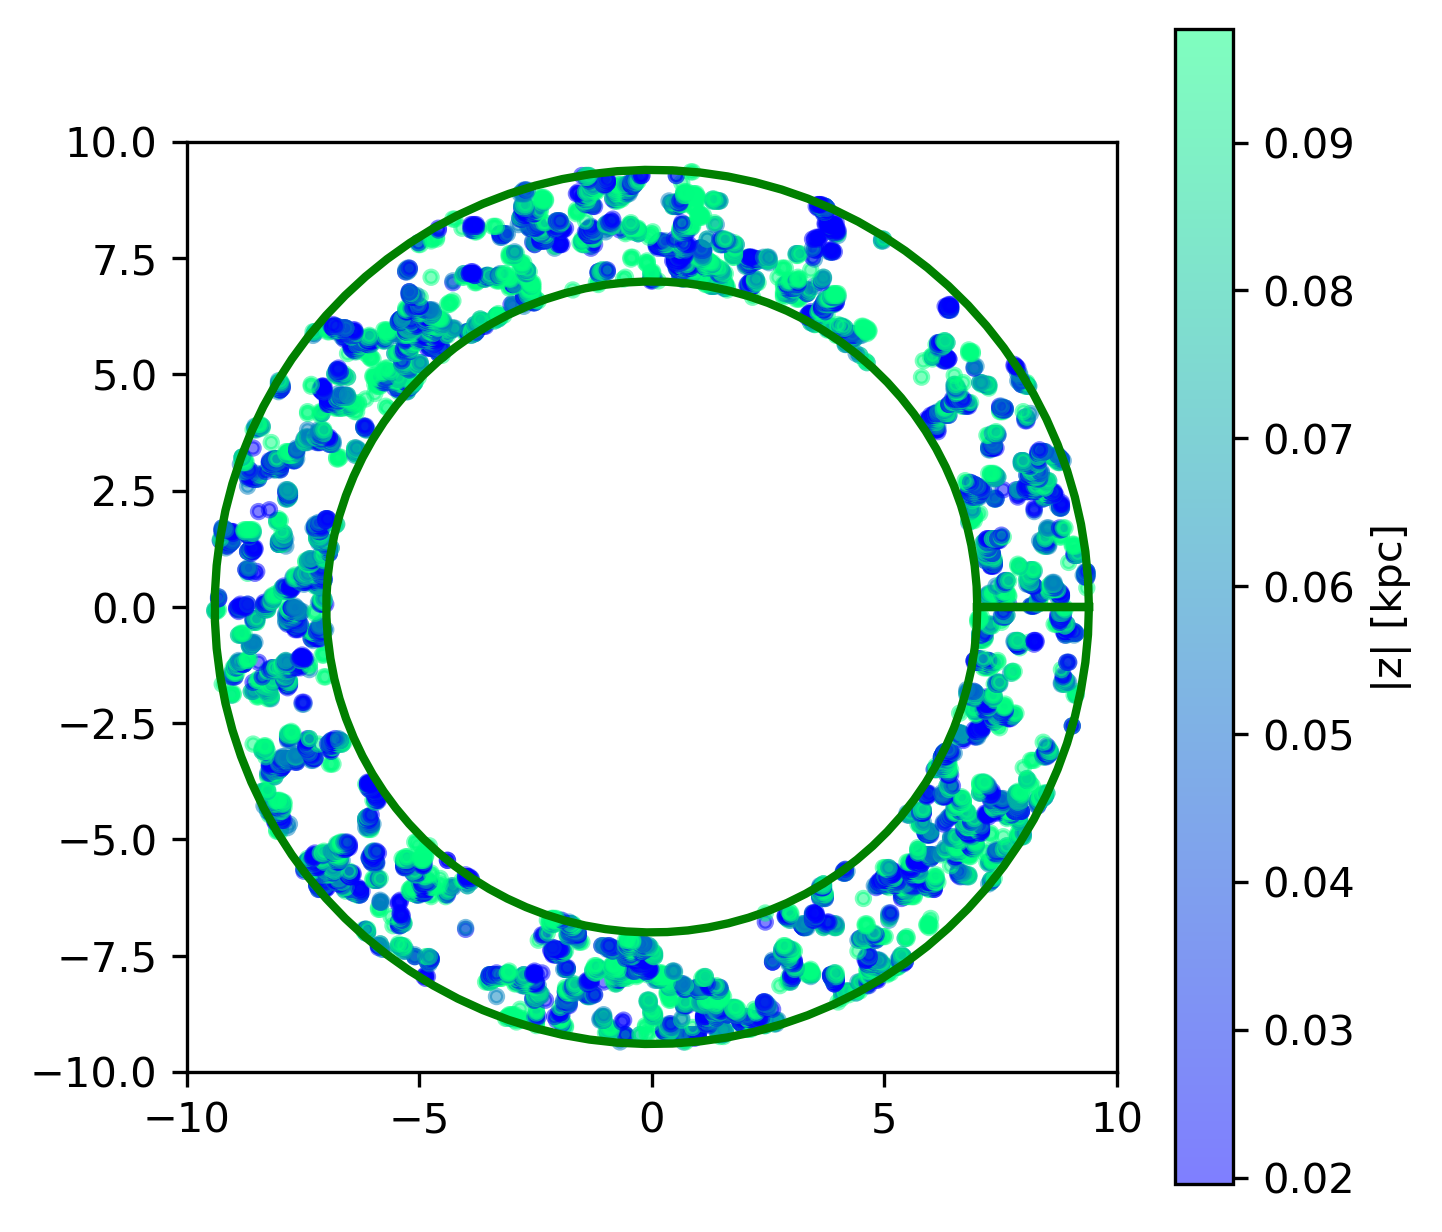

In [24]:
# visualize selected voxels
fig, axs = plt.subplots(1, figsize=(5,5), dpi=300)
scat = axs.scatter(cubes["x"][density_filter], cubes["y"][density_filter], 
                   s=10, alpha=0.5, 
                   c=np.abs(cubes["z"][density_filter]), cmap='winter') #cubes["ioni_gas"][density_filter].value
plt.colorbar(scat, label='|z| [kpc]')
plot_slice_outlines(axs, 1, " ")
axs.set_xlim([-10,10])
axs.set_ylim([-10,10])
# plt.savefig("../visuals/candidate_locations_ioni_gas_averaged_Xe.png", bbox_inches="tight")
plt.show()

## Sample from filtered voxels to select set w/ correct ioni_gas distribution

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from scipy.stats import norm, gaussian_kde

# np.random.seed(3)
np.random.seed(4)

# Target Gaussian distribution
target_mean = 0.018 * u.cm**-3
target_std = 0.002 * u.cm**-3

# Strip units for math
data_vals = cubes["ioni_gas_avg"][density_filter].value

# data_vals = np.random.choice(data_vals, size=1000, replace=False)

# data_vals = data_vals[data_vals > 2*target_mean.value - np.max(data_vals)]

# Estimate proposal PDF using kernel density estimation (KDE)
proposal_kde = gaussian_kde(data_vals)

# Define the target PDF
target_pdf = norm(loc=target_mean.value, scale=target_std.value)

# Calculate acceptance probabilities
proposal_probs = proposal_kde(data_vals)
target_probs = target_pdf.pdf(data_vals)

# Avoid division by zero
acceptance_probs = target_probs / proposal_probs
M = acceptance_probs.max()
acceptance_probs /= M #M  # Normalize so max prob is 1

# Rejection sampling
random_vals = np.random.rand(len(data_vals))
# random_vals = np.random.choice(data_vals, 500, replace=False)
accepted = data_vals[random_vals < acceptance_probs]

# Restore units
accepted_with_units = accepted * cubes["ioni_gas_avg"].unit

# update density_filter
density_filter_with_n_ion = (density_filter[0][random_vals < acceptance_probs],)

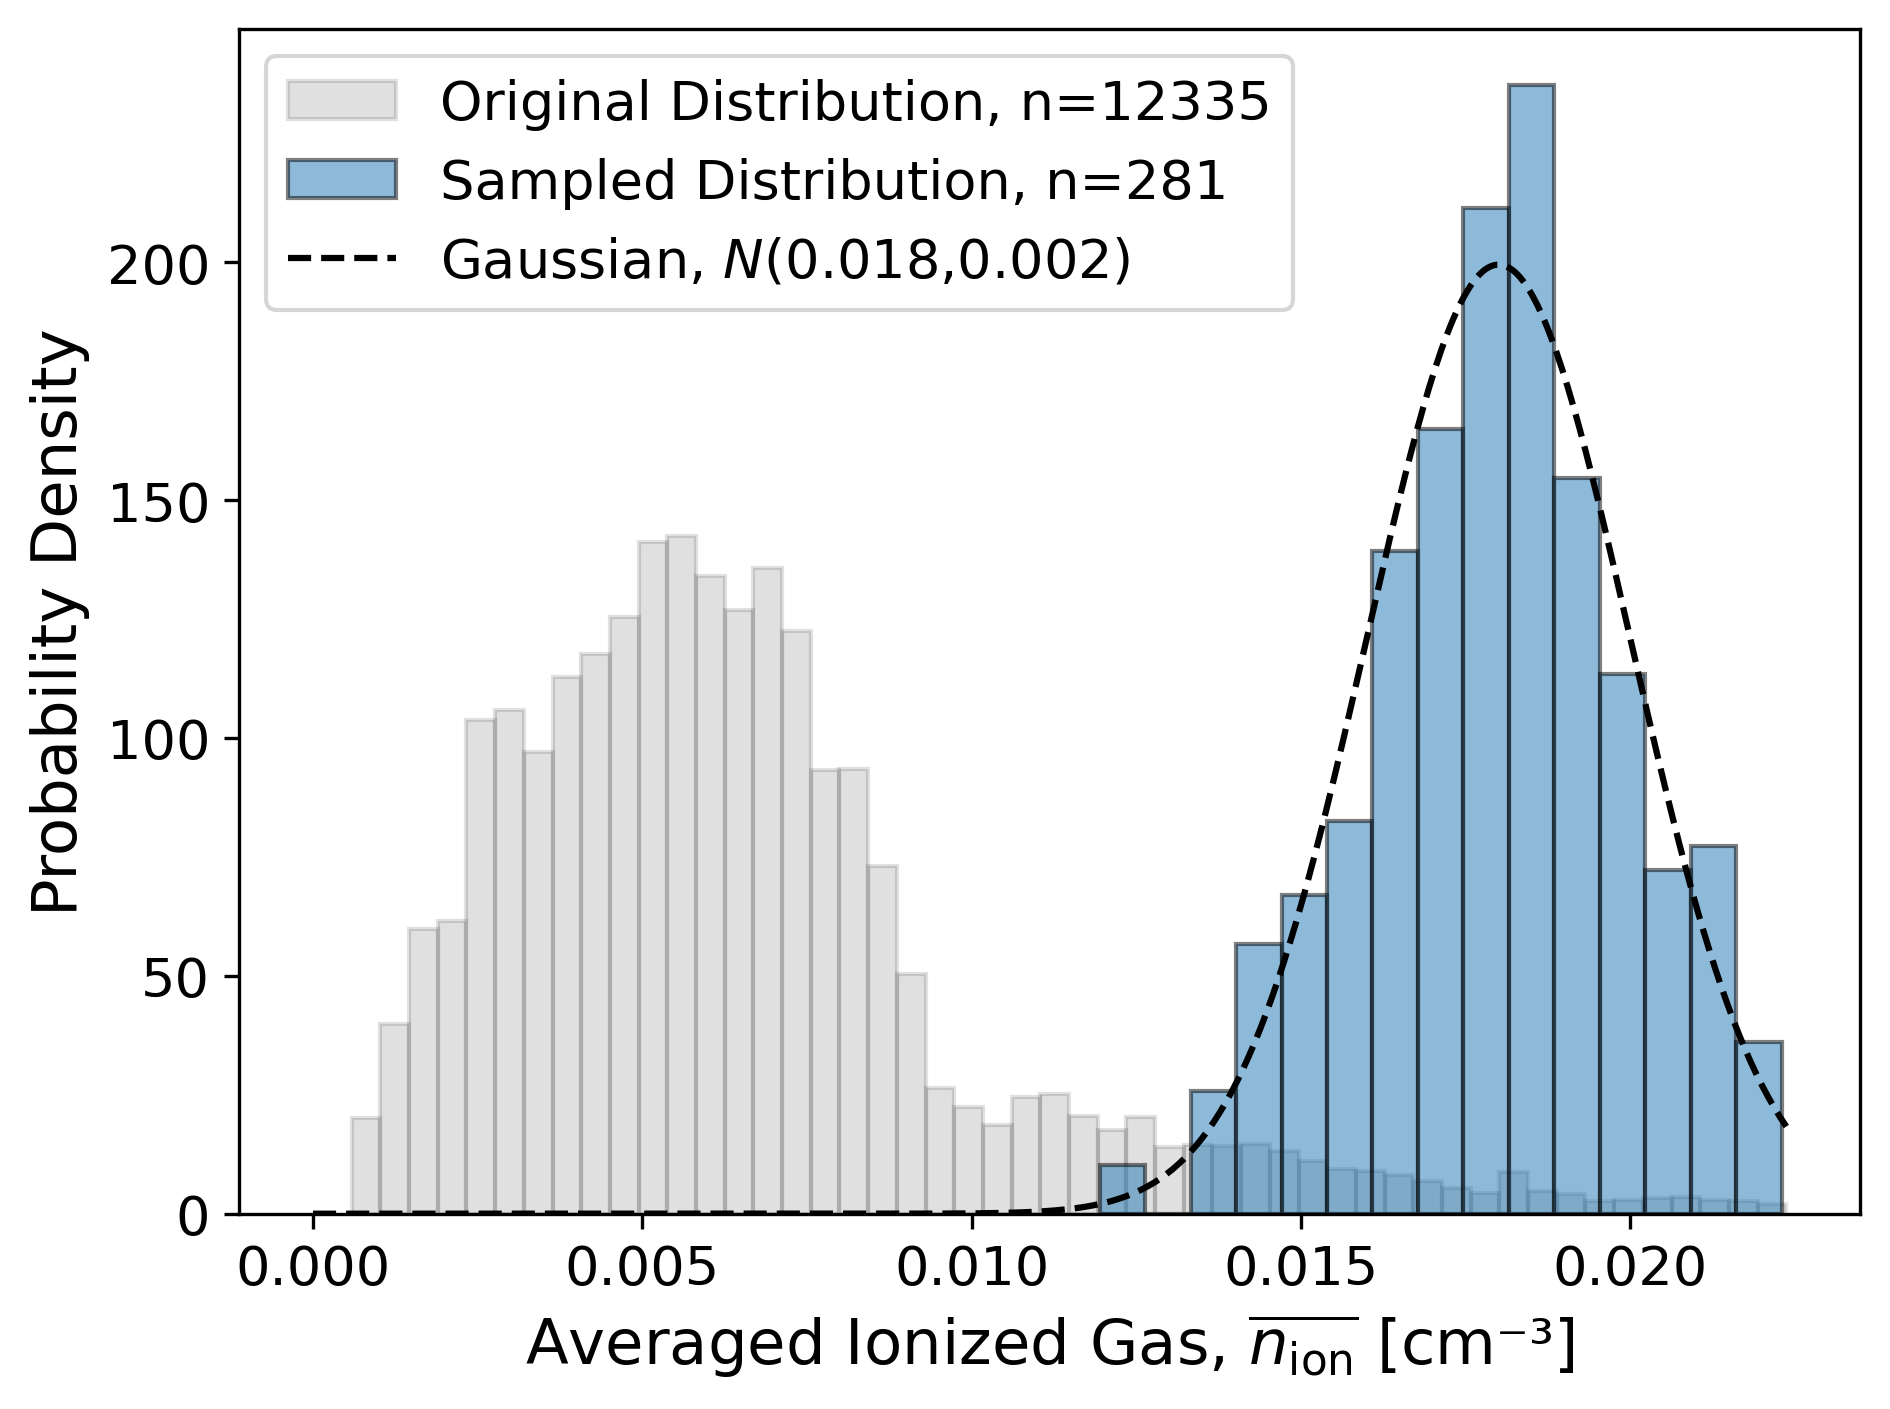

In [26]:
# Plotting
plt.figure(dpi=300)

# Original distribution
bins_new = np.arange(0,0.025, 0.0001)
plt.hist(data_vals, bins=50, density=True, alpha=0.12, color='black', edgecolor='k', 
         label="Original Distribution, n="+str(len(density_filter[0])))
# plt.title("Original Distribution")
plt.xlabel(r"Averaged Ionized Gas, $\overline{n_\text{ion}}$ [cm⁻³]", size=15)
plt.ylabel("Probability Density", size=15)

# Sampled distribution
res = plt.hist(accepted, bins=15, density=True, alpha=0.5, color='C0', edgecolor='k', 
               label='Sampled Distribution, n='+str(len(accepted)))
x = np.linspace(0, max(data_vals), 500)
plt.plot(x, target_pdf.pdf(x), 'k--', 
         label=r'Gaussian, $N$('+str(target_mean.value)+","+str(target_std.value)+")")
plt.legend(fontsize=13)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)


plt.tight_layout()

# plt.savefig("../visuals/ioni_gas_avg_sampling_april_12.pdf", bbox_inches="tight")

plt.show()

In [27]:
# Plotting
plt.figure(dpi=300)

# Original distribution
bins_new = np.arange(0,0.025, 0.0007)
plt.hist(data_vals, bins=bins_new, density=True, alpha=0.12, color='black', edgecolor='k', 
         label="Original Distribution, n="+str(len(density_filter[0])))
# plt.title("Original Distribution")
plt.xlabel(r"Averaged Ionized Gas, $\overline{n_\text{ion}}$ [cm⁻³]", size=15)
plt.ylabel("Probability Density", size=15)

# Sampled distribution
res = plt.hist(accepted, bins=bins_new, density=True, alpha=0.5, color='C0', edgecolor='k', 
               label='Sampled Distribution, n='+str(len(accepted)))
x = np.linspace(0, max(data_vals), 500)
plt.plot(x, target_pdf.pdf(x), 'k--', 
         label=r'Gaussian, $N$('+str(target_mean.value)+","+str(target_std.value)+")")
plt.legend(fontsize=13)
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)


plt.tight_layout()

plt.savefig("../visuals/ioni_gas_avg_sampling_oct_7.pdf", bbox_inches="tight")

plt.show()

SyntaxError: invalid syntax (2908342275.py, line 27)

## Make this the new filtered set of candidate locations

In [28]:
density_filter = density_filter_with_n_ion

In [29]:
print(f"{accepted.shape[0]} candidate locations make up the final filtered set")
print(np.mean(accepted))
print(np.std(accepted))

281 candidate locations make up the final filtered set
0.01795109567875887
0.001943735053526538


## Obtain indexes of voxels around each candidate location

In [30]:
local_height = 1.2
local_width = 1.2
local_radius = 0.6

candidate_regions = {}
full_density_filter = [] #list(density_filter[0])
for i in range(len(density_filter[0])): # random_location_ids: #
    print(f"Processing... {i}", end="\r")
    x_0, y_0, z_0 = cubes["x"][density_filter[0][i]], cubes["y"][density_filter[0][i]], cubes["z"][density_filter[0][i]]
    local_density_filter = np.where(
        (np.sqrt( (cubes["x"] - x_0)**2 + \
                  (cubes["y"] - y_0)**2 + \
                  (cubes["z"] - z_0)**2) < local_radius))
    candidate_regions[density_filter[0][i]] = local_density_filter
    # full_density_filter = full_density_filter + list(local_density_filter[0]) + [density_filter[0][i]]
    full_density_filter = full_density_filter + list(local_density_filter[0])

In [34]:
r = np.sqrt(grid_coords[:,0]**2 + grid_coords[:,1]**2 + grid_coords[:,2]**2)

In [ ]:
# plot final candidate regions

fig, axs = plt.subplots(1, figsize=(5,5), dpi=300)
scat = axs.scatter(cubes["x"][full_density_filter], cubes["y"][full_density_filter], 
                   s=0.5, alpha=0.5, 
                   c=np.abs(cubes["z"][full_density_filter]), cmap='winter') #cubes["ioni_gas"][density_filter].value
plt.colorbar(scat, label='|z| [kpc]')
plot_slice_outlines(axs, 1, " ")
axs.set_xlim([-10,10])
axs.set_ylim([-10,10])
# plt.savefig("../visuals/candidate_locations_surroundings_averaging_Xe.png", bbox_inches="tight")
plt.show()


In [ ]:
fig, axs = plt.subplots(1, figsize=(5,5), dpi=300)
scat = axs.scatter(x[full_density_filter], z[full_density_filter], 
                   s=0.5, alpha=0.5, 
                   c=y[full_density_filter], cmap='winter') #cubes["ioni_gas"][density_filter].value
plt.colorbar(scat, label='y [kpc]')
# plot_slice_outlines(axs, 1, " ")
axs.set_xlim([-10,10])
axs.set_ylim([-1.5,1.5])
# plt.savefig("../visuals/candidate_locations_surroundings_xz.png", bbox_inches="tight")
plt.show()



## Remove duplicates in final voxel selection

In [35]:
full_density_filter_old = full_density_filter
full_density_filter = list(set(full_density_filter))

In [37]:
# full_density_filter

In [41]:
with open("../data/filtered-location-voxels/april-12-2025/full_location_filter.pkl", "wb") as f:
    pickle.dump(full_density_filter, f)

In [61]:
# candidate_regions

with open("../data/filtered-location-voxels/april-12-2025/candidate_regions.pkl", "wb") as f:
    pickle.dump(candidate_regions, f)

## Investigate dv at filtered locations

In [ ]:
plt.figure(dpi=300)
plt.hist(cubes["dv"][list(set(full_density_filter))], bins=np.linspace(1,1000,30)*u.km/u.s, alpha = 0.4, color="black", density=True, edgecolor="black", label="FIRE filtered voxels")
dv_array = np.linspace(1,1000,1000)
v0 = 220
maxwell = f_maxbolt(dv_array, sigma_v = v0/np.sqrt(2), v_b = v0)
plt.plot(dv_array, maxwell, color="blue", label=r"MB, v$_0$=220, $\sigma_{\rm{v}}$=156")
plt.xlabel(r"$\Delta\rm{v}$ $[\mathrm{km}\,\mathrm{s}^{-1}]$", size=15)
plt.ylabel(r"$\rm{P}(\Delta\rm{v})$", size=15)
plt.xlim(0,1000)
plt.legend(fontsize=15)
# plt.grid()
# plt.savefig("../visuals/dv-maxwell-vs-fire.png", bbox_inches = "tight")
plt.savefig("../visuals/dv-maxwell-vs-fire-oct-16.pdf", bbox_inches = "tight")
# plt.vlines(np.mean(cubes["dv"][full_density_filter]).value, 0, 0.0030)
print(np.mean(cubes["dv"][full_density_filter]).value)
print(np.average(dv_array, weights=maxwell))
plt.show()


In [ ]:
plt.figure(dpi=300)
plt.hist(cubes["dv"][full_density_filter], bins=300, alpha = 0.4, color="black", 
         density=False, edgecolor="black", label="FIRE filtered voxels")
dv_array = np.linspace(1,1000,10000)
v0 = 220
maxwell = f_maxbolt(dv_array, sigma_v = v0/np.sqrt(2), v_b = v0) * len(full_density_filter)
plt.plot(dv_array, maxwell, color="blue", label=r"MB, v$_0$=220, $\sigma_{\rm{v}}$=156")
plt.xlabel(r"$\Delta\rm{v}$ [km/s]", size=15)
plt.ylabel(r"$\rm{P}(\Delta\rm{v})$", size=15)
plt.legend(fontsize=15)
plt.savefig("../visuals/dv-maxwell-vs-fire.png", bbox_inches = "tight")
plt.savefig("../visuals/dv-maxwell-vs-fire.pdf", bbox_inches = "tight")
plt.vlines(np.mean(cubes["dv"][full_density_filter]).value, 0, 0.0030)
plt.xlim([0,100])
print(np.mean(cubes["dv"][full_density_filter]).value)
print(np.average(dv_array, weights=maxwell))
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# plt.figure(dpi=300)
fig, axs = plt.subplots(2, 2, dpi=300)
fig.tight_layout()
fig.subplots_adjust(hspace=0.4, wspace=0.2)
keys = ["dark_mat", 'ioni_gas', 'neut_gas', 'temp_ion']
key = 'ioni_gas'

def add_parameter(key, name, legend_name, ax, ay, log=True, color="C0"):
    num_bins_low = 20  # Fewer bins for low values
    num_bins_high = 80  # More bins for high values
    signal = cubes[key][full_density_filter] #quant[key]
    unit = cubes[key][full_density_filter].unit
    
    # low_bins = np.logspace(-60, -4, 1)  # Linear bins for low values
    low_bins = np.linspace(np.min(signal).value,1e-4,2)
    high_bins = np.logspace(-4, np.log10(np.max(signal).value), 12)
    bins = np.unique(np.concatenate((low_bins, high_bins)))           # Merge bins

    if not log:
        bins = np.linspace(np.min(signal).value, 2e-21, 15)

    print(name, np.min(signal).value, np.max(signal).value, np.mean(signal).value)
    
    res = np.histogram(signal.value, bins=bins)  
    
    counts = res[0]  # Raw counts per bin
    bin_widths = np.diff(res[1])  # Bin widths
    probabilities = counts / len(signal.value)  # Fraction of total points in each bin
    
    axs[ax][ay].bar(res[1][:-1], probabilities, width=bin_widths, align='edge', edgecolor='k', 
                    alpha=0.5, color=color)
    axs[ax][ay].vlines(np.mean(signal.value), 0, np.max(probabilities)*10, color=color, 
                       linestyle="--", label = legend_name)
    axs[ax][ay].set_ylim([0,np.max(probabilities)*1.1])
    # axs[ax][ay].plot([0],[0], 's--', color='C0', markerfacecolor='C0', markeredgecolor='black', label='C0 squares + dashed line')
    axs[ax][ay].set_xlabel(name + " [" + str(unit) + "]", size=13)
    if log:
        axs[ax][ay].set_xscale("log")
    if not log:
        axs[ax][ay].xaxis.get_offset_text().set_position((0, -0.05))
        axs[ax][ay].xaxis.offsetText.set_visible(False)
        axs[ax][ay].set_xlabel(name + " [" + "1e-21 "+str(unit) + "]", size=14)

    # # Annotate mean value
    # mean_signal = np.mean(signal.value)
    # plt.text(0.7, 0.95, f"Mean: {mean_signal:.2e}", transform=plt.gca().transAxes, 
    #          fontsize=12, verticalalignment='top', color="black")



add_parameter("ioni_gas", "Ionized Gas", "x", 0, 0, True)
# add_parameter("ioni_gas_c", "Ionized Gas", r"Scaled", 0, 0)
add_parameter("neut_gas", "Neutral Gas", "x", 0, 1)
add_parameter("dark_mat", "Dark Matter", "x", 1, 0, False)
add_parameter("temp_ion", "Gas Temperature", "x", 1, 1)

axs[0][0].set_xlabel( r"Ionized Gas $[\mathrm{cm}^{-3}]$", size=13)
axs[1][0].set_xlabel(r"Dark Matter $[10^{-21}\,\mathrm{kg}\,\mathrm{m}^{-3}]$", size=13)
axs[0][1].set_xlabel( r"Neutral Gas $[\mathrm{cm}^{-3}]$", size=13)

# axs[0][0].legend()
# plt.legend()


# Save and show plot
# plt.savefig("../visuals/parameter-distributions.png", bbox_inches="tight")
plt.savefig("../visuals/parameter-distributions-oct-16.pdf", bbox_inches="tight")
plt.show()


## Prepare cubes for computing epsilon

In [ ]:
# save full list of cubes for processing
full_density_filter = list(set(full_density_filter))
quant = {}
for key in cubes.keys():
    quant[key] = cubes[key][full_density_filter]
del quant["aqn_emit"]
del quant["efrac"]
quant["x"] = quant["x"] * u.kpc
quant["y"] = quant["y"] * u.kpc
quant["z"] = quant["z"] * u.kpc
quant["s"] = quant["s"] * u.kpc
# quant["full_density_filter"] = full_density_filter * u.dimensionless_unscaled
# quant["random_location_ids"] = random_location_ids * u.dimensionless_unscaled
# quant["denisty_filter"] = density_filter * u.dimensionless_unscaled

save_quant(quant, "../data/filtered-location-voxels/april-12-2025/cubes.pkl")

## Import cubes w/ computed epsilon, import location indexing

## March 11 2025

In [28]:
# cubes_m_0_01kg = load_quant("../data/filtered-location-voxels/R-1_6kpc-m-0_01kg.pkl")
# cubes_m_0_1kg = load_quant("../data/filtered-location-voxels/R-1_6kpc-m-0_1kg.pkl")
# cubes_m_0_5kg = load_quant("../data/filtered-location-voxels/R-1_6kpc-m-0_5kg.pkl")

cubes_m_0_01kg = load_quant("../data/filtered-location-voxels/march-11-2025/m-0_01kg-original.pkl")
cubes_m_0_1kg = load_quant("../data/filtered-location-voxels/march-11-2025/m-0_1kg-original.pkl")
cubes_m_0_5kg = load_quant("../data/filtered-location-voxels/march-11-2025/m-0_5kg-original.pkl")

In [29]:
cubes_m_0_01kg_FIRE_dv = load_quant("../data/filtered-location-voxels/march-11-2025/m-0_01kg-FIRE-dv.pkl")
cubes_m_0_1kg_FIRE_dv = load_quant("../data/filtered-location-voxels/march-11-2025/m-0_1kg-FIRE-dv.pkl")
cubes_m_0_5kg_FIRE_dv = load_quant("../data/filtered-location-voxels/march-11-2025/m-0_5kg-FIRE-dv.pkl")

cubes_m_0_01kg_FIRE_dv["aqn_emit"] = np.nan_to_num(cubes_m_0_01kg_FIRE_dv["aqn_emit"], nan=0)
cubes_m_0_1kg_FIRE_dv["aqn_emit"]  = np.nan_to_num(cubes_m_0_1kg_FIRE_dv["aqn_emit"], nan=0)
cubes_m_0_5kg_FIRE_dv["aqn_emit"]  = np.nan_to_num(cubes_m_0_5kg_FIRE_dv["aqn_emit"], nan=0)

In [30]:
cubes_m_0_01kg_no_mod_n_ion = load_quant("../data/filtered-location-voxels/march-11-2025/m-0_01kg-no_mod_n_ion.pkl")
cubes_m_0_1kg_no_mod_n_ion = load_quant("../data/filtered-location-voxels/march-11-2025/m-0_1kg-no_mod_n_ion.pkl")
cubes_m_0_5kg_no_mod_n_ion = load_quant("../data/filtered-location-voxels/march-11-2025/m-0_5kg-no_mod_n_ion.pkl")

## April 9 2025

In [ ]:
cubes_m_0_01kg = load_quant("../data/filtered-location-voxels/april-9-2025/m-0_01kg-original.pkl")
cubes_m_0_1kg = load_quant("../data/filtered-location-voxels/april-9-2025/m-0_1kg-original.pkl")
cubes_m_0_5kg = load_quant("../data/filtered-location-voxels/april-9-2025/m-0_5kg-original.pkl")

cubes_m_0_01kg_FIRE_dv = load_quant("../data/filtered-location-voxels/april-9-2025/m-0_01kg-FIRE-dv.pkl")
cubes_m_0_1kg_FIRE_dv = load_quant("../data/filtered-location-voxels/april-9-2025/m-0_1kg-FIRE-dv.pkl")
cubes_m_0_5kg_FIRE_dv = load_quant("../data/filtered-location-voxels/april-9-2025/m-0_5kg-FIRE-dv.pkl")

cubes_m_0_01kg_FIRE_dv["aqn_emit"] = np.nan_to_num(cubes_m_0_01kg_FIRE_dv["aqn_emit"], nan=0)
cubes_m_0_1kg_FIRE_dv["aqn_emit"]  = np.nan_to_num(cubes_m_0_1kg_FIRE_dv["aqn_emit"], nan=0)
cubes_m_0_5kg_FIRE_dv["aqn_emit"]  = np.nan_to_num(cubes_m_0_5kg_FIRE_dv["aqn_emit"], nan=0)

## April 12 2025

In [43]:
cubes_m_0_01kg = load_quant("../data/filtered-location-voxels/april-12-2025/m-0_01kg-original.pkl")
cubes_m_0_1kg = load_quant("../data/filtered-location-voxels/april-12-2025/m-0_1kg-original.pkl")
cubes_m_0_5kg = load_quant("../data/filtered-location-voxels/april-12-2025/m-0_5kg-original.pkl")

cubes_m_0_01kg_FIRE_dv = load_quant("../data/filtered-location-voxels/april-12-2025/m-0_01kg-FIRE-dv.pkl")
cubes_m_0_1kg_FIRE_dv = load_quant("../data/filtered-location-voxels/april-12-2025/m-0_1kg-FIRE-dv.pkl")
cubes_m_0_5kg_FIRE_dv = load_quant("../data/filtered-location-voxels/april-12-2025/m-0_5kg-FIRE-dv.pkl")

cubes_m_0_01kg_FIRE_dv["aqn_emit"] = np.nan_to_num(cubes_m_0_01kg_FIRE_dv["aqn_emit"], nan=0)
cubes_m_0_1kg_FIRE_dv["aqn_emit"]  = np.nan_to_num(cubes_m_0_1kg_FIRE_dv["aqn_emit"], nan=0)
cubes_m_0_5kg_FIRE_dv["aqn_emit"]  = np.nan_to_num(cubes_m_0_5kg_FIRE_dv["aqn_emit"], nan=0)

with open("../data/filtered-location-voxels/april-12-2025/full_location_filter.pkl", "rb") as f:
    full_density_filter = pickle.load(f)
with open("../data/filtered-location-voxels/april-12-2025/candidate_regions.pkl", "rb") as f:
    candidate_regions = pickle.load(f)

In [44]:
enforce_units(cubes)
cubes

{'aqn_emit': <Quantity [1., 1., 1., ..., 1., 1., 1.] ph / (Angstrom s sr cm3)>,
 'dark_mat': <Quantity [1.42159768e-22, 1.42159768e-22, 1.42159768e-22, ...,
            5.29799665e-23, 5.29799665e-23, 5.29799665e-23] kg / m3>,
 'efrac': array([1.16713503, 1.16713503, 1.16713503, ..., 1.16818657, 1.16818657,
        1.16818657]),
 'temp_ion': <Quantity [ 96.56496446,  96.56496446,  96.56496446, ..., 212.16054101,
            212.16054101, 212.16054101] eV>,
 'gas': <Quantity [0.00135666, 0.00135666, 0.00135666, ..., 0.00039591, 0.00039591,
            0.00039591] 1 / cm3>,
 'dv': <Quantity [303.71247815, 303.71247815, 303.71247815, ..., 160.42194097,
            160.42194097, 160.42194097] km / s>,
 'ioni_gas': <Quantity [0.00158341, 0.00158341, 0.00158341, ..., 0.0004625 , 0.0004625 ,
            0.0004625 ] 1 / cm3>,
 'neut_gas': <Quantity [1.72466558e-04, 1.72466558e-04, 1.72466558e-04, ...,
            4.99140533e-05, 4.99140533e-05, 4.99140533e-05] 1 / cm3>,
 's': array([14.1145142

## Histograms of T_AQN

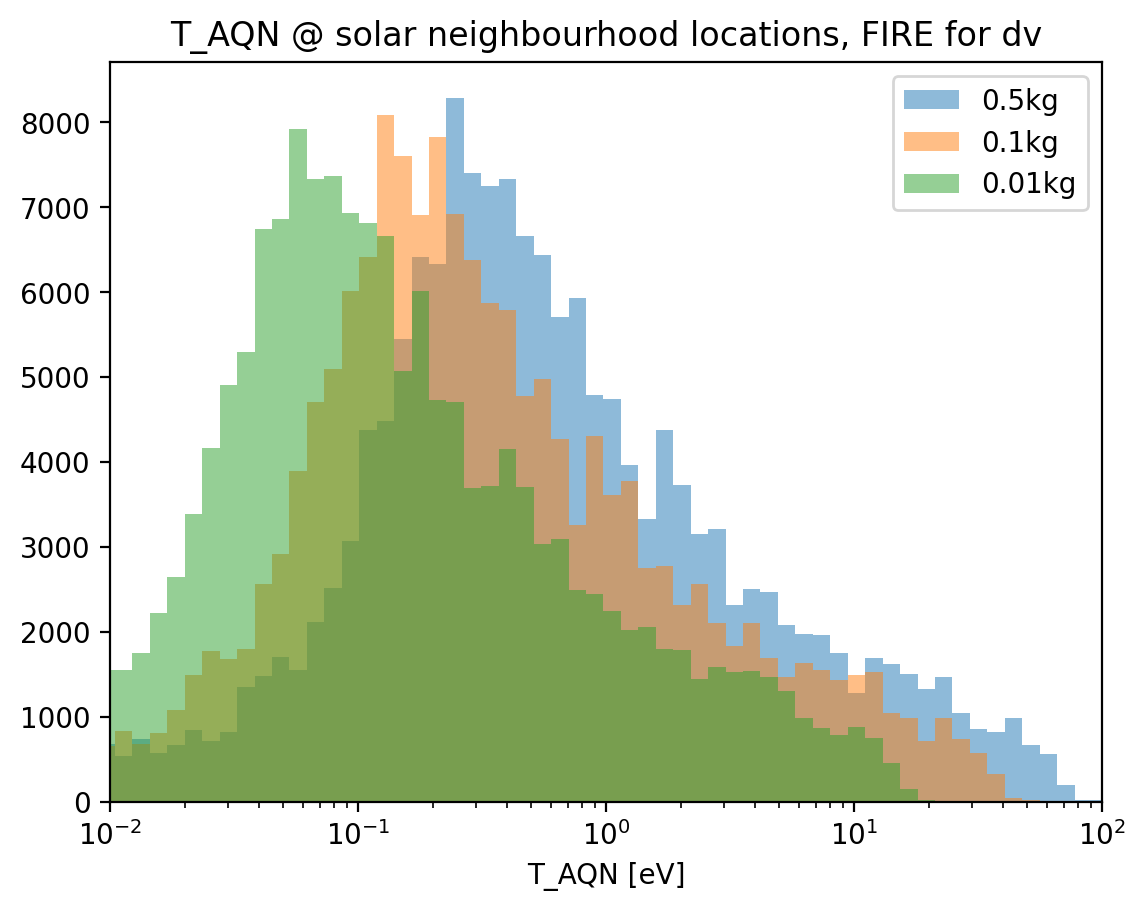

In [45]:
plt.figure(dpi=200)
m_aqn_kg = 0.5 * u.kg
cubes = cubes_m_0_5kg_FIRE_dv.copy()
enforce_units(cubes)
R_aqn_cm = calc_R_AQN(m_aqn_kg)
cubes["dark_mat"] = cubes["dark_mat"] * 2/5
cubes["temp_ion_eff"] = cubes["temp_ion"] + 1/2 * cst.m_p * kg_to_eV * cubes["dv_ioni"]**2
res =  T_AQN_ionized2(  cubes["ioni_gas"], cubes["dv_ioni"], f, g, 
                                        cubes["temp_ion_eff"], R_aqn_cm)
plt.hist(res.value, bins=np.logspace(-10,4,200), log=False, label="0.5kg", alpha=0.5)

m_aqn_kg = 0.1 * u.kg
cubes = cubes_m_0_1kg_FIRE_dv.copy()
enforce_units(cubes)
R_aqn_cm = calc_R_AQN(m_aqn_kg)
cubes["dark_mat"] = cubes["dark_mat"] * 2/5
cubes["temp_ion_eff"] = cubes["temp_ion"] + 1/2 * cst.m_p * kg_to_eV * cubes["dv_ioni"]**2
res =  T_AQN_ionized2(  cubes["ioni_gas"], cubes["dv_ioni"], f, g, 
                                        cubes["temp_ion_eff"], R_aqn_cm)
plt.hist(res.value, bins=np.logspace(-10,4,200), log=False, label="0.1kg", alpha=0.5)

m_aqn_kg = 0.01 * u.kg
cubes = cubes_m_0_01kg_FIRE_dv.copy()
enforce_units(cubes)
R_aqn_cm = calc_R_AQN(m_aqn_kg)
cubes["dark_mat"] = cubes["dark_mat"] * 2/5
cubes["temp_ion_eff"] = cubes["temp_ion"] + 1/2 * cst.m_p * kg_to_eV * cubes["dv_ioni"]**2
res =  T_AQN_ionized2(  cubes["ioni_gas"], cubes["dv_ioni"], f, g, 
                                        cubes["temp_ion_eff"], R_aqn_cm)
plt.hist(res.value, bins=np.logspace(-10,4,200), log=False, label="0.01kg", alpha=0.5)

plt.xlim(1e-2, 100)
plt.xlabel("T_AQN [eV]")
plt.xscale("log")
plt.title("T_AQN @ solar neighbourhood locations, FIRE for dv")
plt.legend()
plt.show()



In [ ]:
def T_aqn_velocity_integrand(v, quant, sigma_v, v_b, m_aqn_kg, band_min, band_max, adjust_T_gas):
    
    if quant["ioni_gas"].value < 1e-6:
        return np.array([0])

    else:
        f_res = f_maxbolt(v, sigma_v, v_b)
        quant["dv_ioni"] = (v*u.km/u.s) / cst.c.to(u.km/u.s)
        t_aqn_res = compute_epsilon_ionized_bandwidth(quant, m_aqn_kg, band_min, band_max, adjust_T_gas)["t_aqn_i"].value # _bandwidth

        return t_aqn_res * f_res
def process_batch(quant, m_aqn_kg, band_min, band_max, adjust_T_gas, sigma_v, v_b):
        
    quant_count = len(quant["dark_mat"])
    
    if quant_count == 0:
        
        return []
        
    else:
        batches = split_quant(quant, quant_count)
        
        batch_results = []

        for i in range(quant_count):
            
            batch_results.append(quad(T_aqn_velocity_integrand, 0.1, 1*(sigma_v.value+v_b.value), 
                args=(batches[i], sigma_v.value, v_b.value, m_aqn_kg, band_min, band_max, adjust_T_gas))[0])

        return batch_results * u.eV


v_b = 220 * u.km/u.s
sigma_v = v_b / np.sqrt(2)


m_aqn_kg = 0.5 * u.kg
process_batch(cubes_m_0_5kg, m_aqn_kg, wavel_min, wavel_max, True, sigma_v, v_b)


In [ ]:
plt.figure(dpi=200)
m_aqn_kg = 0.5 * u.kg
cubes = cubes_m_0_5kg_FIRE_dv.copy()
enforce_units(cubes)
R_aqn_cm = calc_R_AQN(m_aqn_kg)
cubes["dark_mat"] = cubes["dark_mat"] * 2/5
cubes["temp_ion_eff"] = cubes["temp_ion"] + 1/2 * cst.m_p * kg_to_eV * cubes["dv_ioni"]**2
res =  T_AQN_ionized2(  cubes["ioni_gas"], cubes["dv_ioni"], f, g, 
                                        cubes["temp_ion_eff"], R_aqn_cm)
plt.hist(res.value, bins=np.logspace(-10,4,200), log=False, label="0.5kg", alpha=0.5)

m_aqn_kg = 0.1 * u.kg
cubes = cubes_m_0_1kg_FIRE_dv.copy()
enforce_units(cubes)
R_aqn_cm = calc_R_AQN(m_aqn_kg)
cubes["dark_mat"] = cubes["dark_mat"] * 2/5
cubes["temp_ion_eff"] = cubes["temp_ion"] + 1/2 * cst.m_p * kg_to_eV * cubes["dv_ioni"]**2
res =  T_AQN_ionized2(  cubes["ioni_gas"], cubes["dv_ioni"], f, g, 
                                        cubes["temp_ion_eff"], R_aqn_cm)
plt.hist(res.value, bins=np.logspace(-10,4,200), log=False, label="0.1kg", alpha=0.5)

m_aqn_kg = 0.01 * u.kg
cubes = cubes_m_0_01kg_FIRE_dv.copy()
enforce_units(cubes)
R_aqn_cm = calc_R_AQN(m_aqn_kg)
cubes["dark_mat"] = cubes["dark_mat"] * 2/5
cubes["temp_ion_eff"] = cubes["temp_ion"] + 1/2 * cst.m_p * kg_to_eV * cubes["dv_ioni"]**2
res =  T_AQN_ionized2(  cubes["ioni_gas"], cubes["dv_ioni"], f, g, 
                                        cubes["temp_ion_eff"], R_aqn_cm)
plt.hist(res.value, bins=np.logspace(-10,4,200), log=False, label="0.01kg", alpha=0.5)

plt.xlim(1e-2, 100)
plt.xlabel("T_AQN [eV]")
plt.xscale("log")
plt.title("T_AQN @ solar neighbourhood locations, FIRE for dv")
plt.legend()
plt.show()



## Compute Phi

In [87]:
full_density_filter_set = list(set(full_density_filter))
full_density_filter_set = full_density_filter
voxel_volume = (cube_length / voxel_resolution * u.kpc)**3
wavel_mean = (wavel_max - wavel_min)/2
keys = list(candidate_regions.keys())

In [90]:
final_aqn_signal = {}
final_aqn_signal[0.01] = []# * photon_units
final_aqn_signal[0.1] = [] #* photon_units
final_aqn_signal[0.5] = [] #* photon_units

final_aqn_signal_FIRE_dv = {}
final_aqn_signal_FIRE_dv[0.01] = [] #* photon_units
final_aqn_signal_FIRE_dv[0.1]  = [] #* photon_units
final_aqn_signal_FIRE_dv[0.5]  = [] #* photon_units

cubes_list = [cubes_m_0_01kg, cubes_m_0_1kg, cubes_m_0_5kg]
cubes_list_FIRE_dv = [cubes_m_0_01kg_FIRE_dv, cubes_m_0_1kg_FIRE_dv, cubes_m_0_5kg_FIRE_dv]

m_list = [0.01, 0.1, 0.5]

In [60]:
# keys

### MB dv

In [91]:
# for each AQN mass...
for j in range(3):
    
    quant = cubes_list[j].copy()

    # for each candidate location...
    for i in range(len(keys)):
        candidate = np.where(full_density_filter_set == keys[i])

        candidate_region = candidate_regions[keys[i]][0][candidate_regions[keys[i]][0] != keys[i]]
        
        candidate_filter = [k in candidate_region for k in full_density_filter_set]

        # find the distance to each surrounding voxel
        r_squared = (quant["x"][candidate_filter] - quant["x"][candidate])**2 + \
                    (quant["y"][candidate_filter] - quant["y"][candidate])**2 + \
                    (quant["z"][candidate_filter] - quant["z"][candidate])**2

        # compute Phi
        final_aqn_signal[m_list[j]].append(((voxel_volume / (4 * np.pi )) * np.sum(quant["aqn_emit"][candidate_filter] / r_squared )).to(photon_units))

        print(f"{m_list[j]}: {i}/{len(keys)}            ", end="\r")

KeyboardInterrupt: 

### FIRE dv

In [62]:
for j in range(3):
    
    quant = cubes_list_FIRE_dv[j].copy()
    
    for i in range(len(keys)):
        candidate = np.where(full_density_filter_set == keys[i])

        candidate_region = candidate_regions[keys[i]][0][candidate_regions[keys[i]][0] != keys[i]]
        
        candidate_filter = [k in candidate_region for k in full_density_filter_set]
        
        r_squared = (quant["x"][candidate_filter] - quant["x"][candidate])**2 + \
                    (quant["y"][candidate_filter] - quant["y"][candidate])**2 + \
                    (quant["z"][candidate_filter] - quant["z"][candidate])**2
        
        final_aqn_signal_FIRE_dv[m_list[j]].append(((voxel_volume / (4 * np.pi )) * np.sum(quant["aqn_emit"][candidate_filter] / r_squared )).to(photon_units))

        print(f"{m_list[j]}: {i}/{len(keys)}            ", end="\r")

In [77]:
for m in m_list:
    final_aqn_signal[m] = [i.value for i in final_aqn_signal[m]]
    final_aqn_signal_FIRE_dv[m] = [i.value for i in final_aqn_signal_FIRE_dv[m]]

In [85]:
for m in m_list:
    final_aqn_signal[m] = np.array(final_aqn_signal[m])  * photon_units
    final_aqn_signal_FIRE_dv[m] = np.array(final_aqn_signal_FIRE_dv[m]) * photon_units

In [73]:
# final_aqn_signal

### Save computed signal

In [ ]:
# np.save("../data/filtered-location-voxels/april-12-2025/aqn-signal-m-0_01kg-original.npy", np.array(final_aqn_signal[0.01]))
# np.save("../data/filtered-location-voxels/april-12-2025/aqn-signal-m-0_1kg-original.npy",  np.array(final_aqn_signal[0.1]))
# np.save("../data/filtered-location-voxels/april-12-2025/aqn-signal-m-0_5kg-original.npy",  np.array(final_aqn_signal[0.5]))

# np.save("../data/filtered-location-voxels/april-12-2025/aqn-signal-m-0_01kg-FIRE-dv.npy", np.array(final_aqn_signal_FIRE_dv[0.01]))
# np.save("../data/filtered-location-voxels/april-12-2025/aqn-signal-m-0_1kg-FIRE-dv.npy",  np.array(final_aqn_signal_FIRE_dv[0.1]))
# np.save("../data/filtered-location-voxels/april-12-2025/aqn-signal-m-0_5kg-FIRE-dv.npy",  np.array(final_aqn_signal_FIRE_dv[0.5]))

### Or load in previous calculation

In [88]:
final_aqn_signal = {}

final_aqn_signal[0.01] = np.load("../data/filtered-location-voxels/april-12-2025/aqn-signal-m-0_01kg-original.npy") * photon_units
final_aqn_signal[0.1] = np.load("../data/filtered-location-voxels/april-12-2025/aqn-signal-m-0_1kg-original.npy") * photon_units
final_aqn_signal[0.5] = np.load("../data/filtered-location-voxels/april-12-2025/aqn-signal-m-0_5kg-original.npy") * photon_units

final_aqn_signal_FIRE_dv = {}

final_aqn_signal_FIRE_dv[0.01] = np.load("../data/filtered-location-voxels/april-12-2025/aqn-signal-m-0_01kg-FIRE-dv.npy") * photon_units
final_aqn_signal_FIRE_dv[0.1] = np.load("../data/filtered-location-voxels/april-12-2025/aqn-signal-m-0_1kg-FIRE-dv.npy") * photon_units
final_aqn_signal_FIRE_dv[0.5] = np.load("../data/filtered-location-voxels/april-12-2025/aqn-signal-m-0_5kg-FIRE-dv.npy") * photon_units

In [41]:
# final_aqn_signal_FIRE_dv[0.01]

In [64]:
def plot_aqn_histogram_cumulative_updated(fig, ax, linetype, signal, m_aqn, xlimmax):
    unit   = signal.unit
    
    max_signal = np.max(signal.value)
    
    print(f'Maximum value is {max_signal}')
    
    bins = np.linspace(0,xlimmax,50000)
    
    res = np.histogram(signal.value, bins=bins)
    indices = np.digitize(signal.value, bins)

    counts = res[0] 
    bin_widths = np.diff(res[1])  # Bin widths
    probabilities = 1 - np.cumsum(counts) / len(signal)  # Fraction of total points in each bin

    ax.step(res[1][:-1], probabilities, where='post', lw=2, label=m_aqn+" kg", linestyle=linetype)

    mean_signal = np.mean(signal.value)
    
    ax.axvspan(100, 200, color='lightblue', alpha=0.5)

    ax.set_xscale("log")
    ax.set_xlim(1e1,xlimmax)


# plt.close()
# fig, ax = plt.subplots(dpi=300)

# xlimmax = 1000

# # plot_aqn_histogram_cumulative(fig, ax, "-", cubes_m_0_5kg.copy(), "0.5", xlimmax=xlimmax)
# # plot_aqn_histogram_cumulative(fig, ax, "--", cubes_m_0_1kg.copy(), "0.1", xlimmax=xlimmax)
# # plot_aqn_histogram_cumulative(fig, ax, "-.", cubes_m_0_01kg.copy(), "0.01", xlimmax=xlimmax)

# plot_aqn_histogram_cumulative_updated(fig, ax, "-", final_aqn_signal[0.5].copy(), "0.5", xlimmax=xlimmax)
# plot_aqn_histogram_cumulative_updated(fig, ax, "--", final_aqn_signal[0.1].copy(), "0.1", xlimmax=xlimmax)
# plot_aqn_histogram_cumulative_updated(fig, ax, "-.", final_aqn_signal[0.01].copy(), "0.01", xlimmax=xlimmax)

# plot_aqn_histogram_cumulative_updated(fig, ax, "-", final_aqn_signal_FIRE_dv[0.5].copy(), "0.5", xlimmax=xlimmax)
# plot_aqn_histogram_cumulative_updated(fig, ax, "--", final_aqn_signal_FIRE_dv[0.1].copy(), "0.1", xlimmax=xlimmax)
# plot_aqn_histogram_cumulative_updated(fig, ax, "-.", final_aqn_signal_FIRE_dv[0.01].copy(), "0.01", xlimmax=xlimmax)

# plt.legend(fontsize=14)

# plt.show()

In [65]:
def plot_aqn_histogram_updated(fig, ax, linetype, signal, m_aqn, bins, color):
    unit   = signal.unit
    
    max_signal = np.max(signal.value)
    print(signal.shape)
    print(f'Maximum value is {max_signal}')


    ax.hist(signal.value, bins=bins, density=True, alpha=0.4, edgecolor='k', label=m_aqn+" kg") #color=color, 
    
    # res = np.histogram(signal.value, bins=bins)

    # counts = res[0] 
    # bin_widths = np.diff(res[1])  # Bin widths
    # probabilities = 1 - np.cumsum(counts) / len(signal)  # Fraction of total points in each bin

    # ax.step(res[1][:-1], res[0], where='post', lw=2, label=m_aqn+" kg", linestyle=linetype)

    mean_signal = np.mean(signal.value)
    
    # ax.axvspan(100, 200, color='lightblue', alpha=0.5)

    ax.set_yscale("log")
    ax.set_xscale("log")
    # ax.set_xlim(1e1,xlimmax)

### Combined histograms of all regions

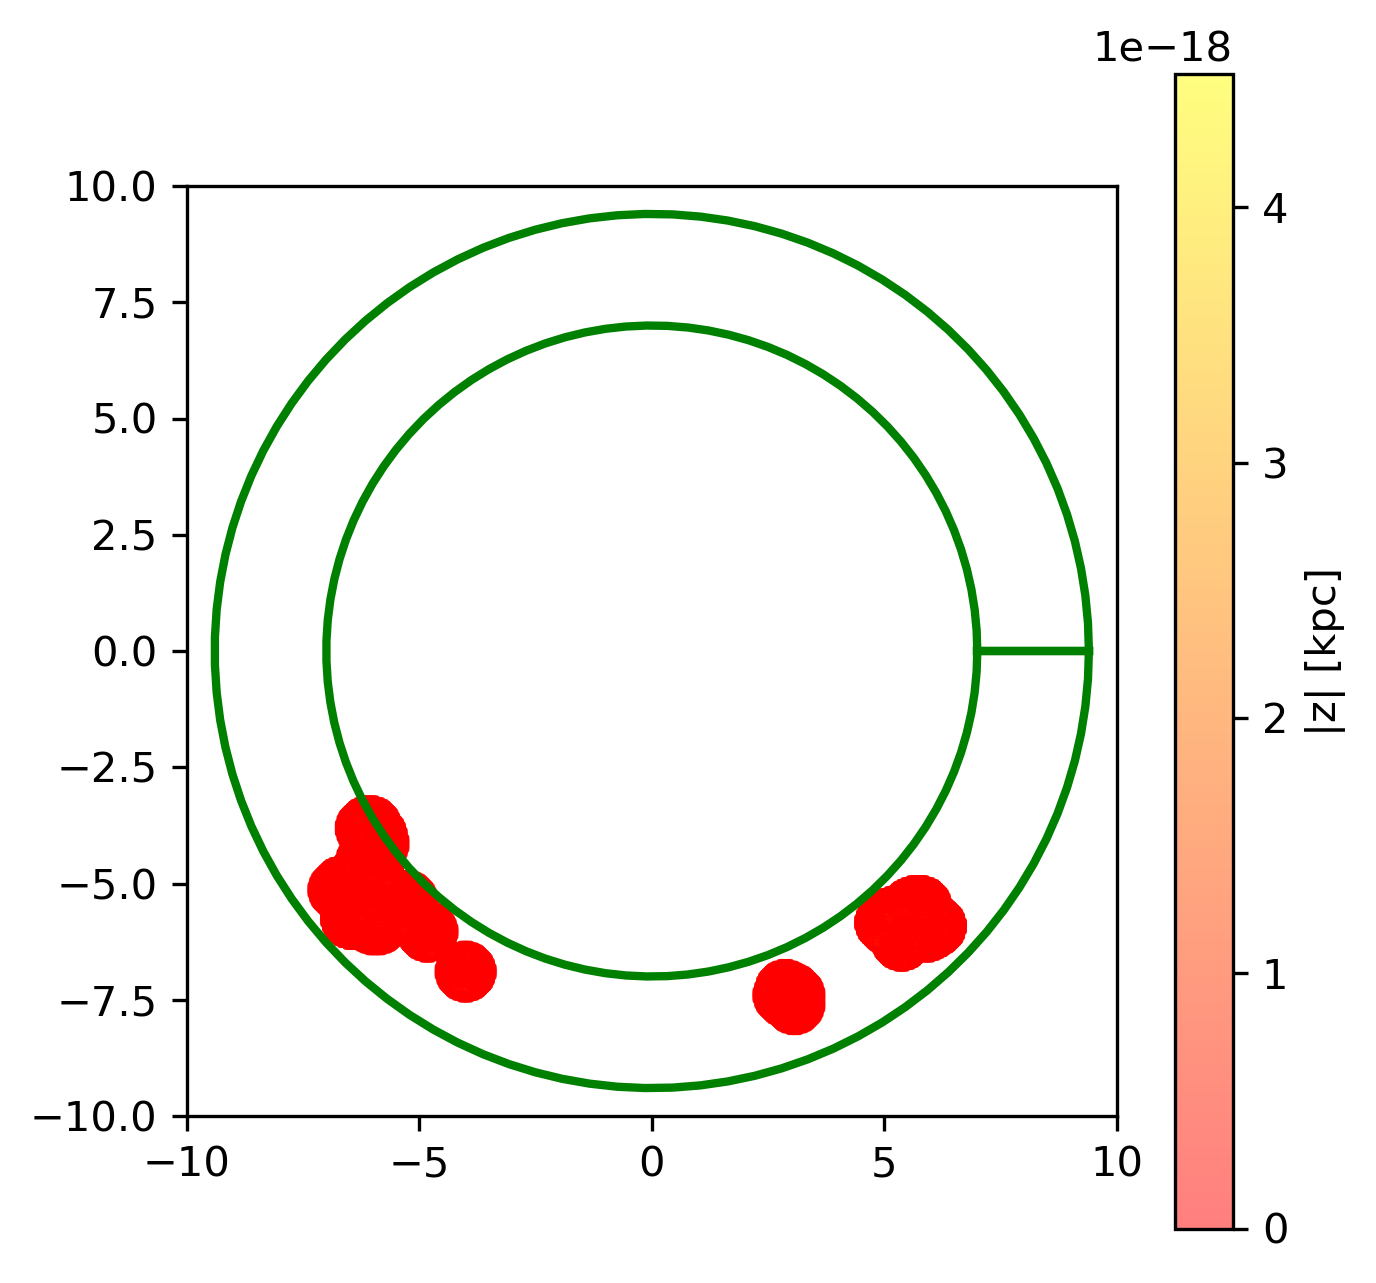

In [54]:
fig, axs = plt.subplots(1, figsize=(5,5), dpi=300)
scat = axs.scatter(cubes_m_0_01kg["x"].value, cubes_m_0_01kg["y"].value, 
                   s=0.5, alpha=0.5, 
                   c=cubes_m_0_01kg["aqn_emit"].value, cmap='autumn') #cubes["ioni_gas"][density_filter].value
plt.colorbar(scat, label='|z| [kpc]')
plot_slice_outlines(axs, 1, " ")
axs.set_xlim([-10,10])
axs.set_ylim([-10,10])
plt.show()

In [ ]:
quant = cubes_m_0_5kg.copy()

to_photon_units = (0.6*u.kpc).to(u.cm)/(4*np.pi)
signal = quant["aqn_emit"] * to_photon_units
signal = final_aqn_signal[0.1]
unit   = signal.unit


low_bins = np.linspace(0, 50, 20)  
high_bins = np.linspace(50, 3e4, 2)                    
bins = np.unique(np.concatenate((low_bins, high_bins)))  
low_end = np.where(bins==high_bins[0])[0][0]
# print(low_end[0][0])
res = np.histogram(signal.value, bins=bins)
counts = res[0] 
bin_widths = np.diff(res[1])  # Bin widths
probabilities = counts / len(signal)  # Fraction of total points in each bin

plt.figure(dpi=300)
plt.bar(res[1][:-1], probabilities, width=bin_widths, align='edge', edgecolor='k')

# # Annotate the probabilities on each bar
for k in range(len(probabilities)):
    if k == low_end:
        bin_center = res[1][k] #+ res[1][k + 1]) / 2
        plt.text(70, 1e-2, f'{probabilities[k]*100:.1f} % ----------->', #f'{probabilities[k]*100:.1e} %', 
                 ha='center', va='bottom', fontsize=15, rotation=0)



mean_signal = np.mean(signal.value)

plt.vlines(mean_signal, 0, np.max(probabilities)*100, color="red")

# # Set scale and labels
# plt.xscale("log")
plt.yscale("log")
plt.ylabel("Probability", size=14)
plt.xlabel(unit, size=14)
# plt.xlabel(key + " [" + str(unit) + "]", size=14)
plt.ylim([0,1])
plt.xlim([0,100])


plt.text(0.11, 0.95, f"M_aqn: 0.1 kg\nMean: {mean_signal:.2e}", transform=plt.gca().transAxes, 
         fontsize=12, verticalalignment='top', color="red")


# === Inset axis for the second range ===
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
res = np.histogram(signal.value, bins = np.linspace(50, 3e4, 20))
counts = res[0]  # Raw counts per bin
print(np.sum(counts))

bin_widths = np.diff(res[1])  # Bin widths
probabilities = counts / len(signal)  # Fraction of total points in each bin

# Create inset
ax_inset = inset_axes(plt.gca(), width="50%", height="35%", loc="upper right",  borderpad=1)
ax_inset.bar(res[1][:-1], probabilities, width=bin_widths, align='edge', edgecolor='k')
# ax_inset.set_xscale("log")
ax_inset.set_xlim([100, 3e4])  # Second range
ax_inset.set_yscale("log")
ax_inset.set_xticks([50, 1e4, 3e4])  # Add ticks for clarity
ax_inset.tick_params(labelsize=6)

# Draw break lines (optional visual cue)
plt.gca().spines['right'].set_linestyle("--")
ax_inset.spines['left'].set_linestyle("--")


# # Save and show plot
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-m-0_1kg.png", bbox_inches="tight")
plt.show()


/tmp/ipykernel_70/1395476332.py:40: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim([0,1])


50976


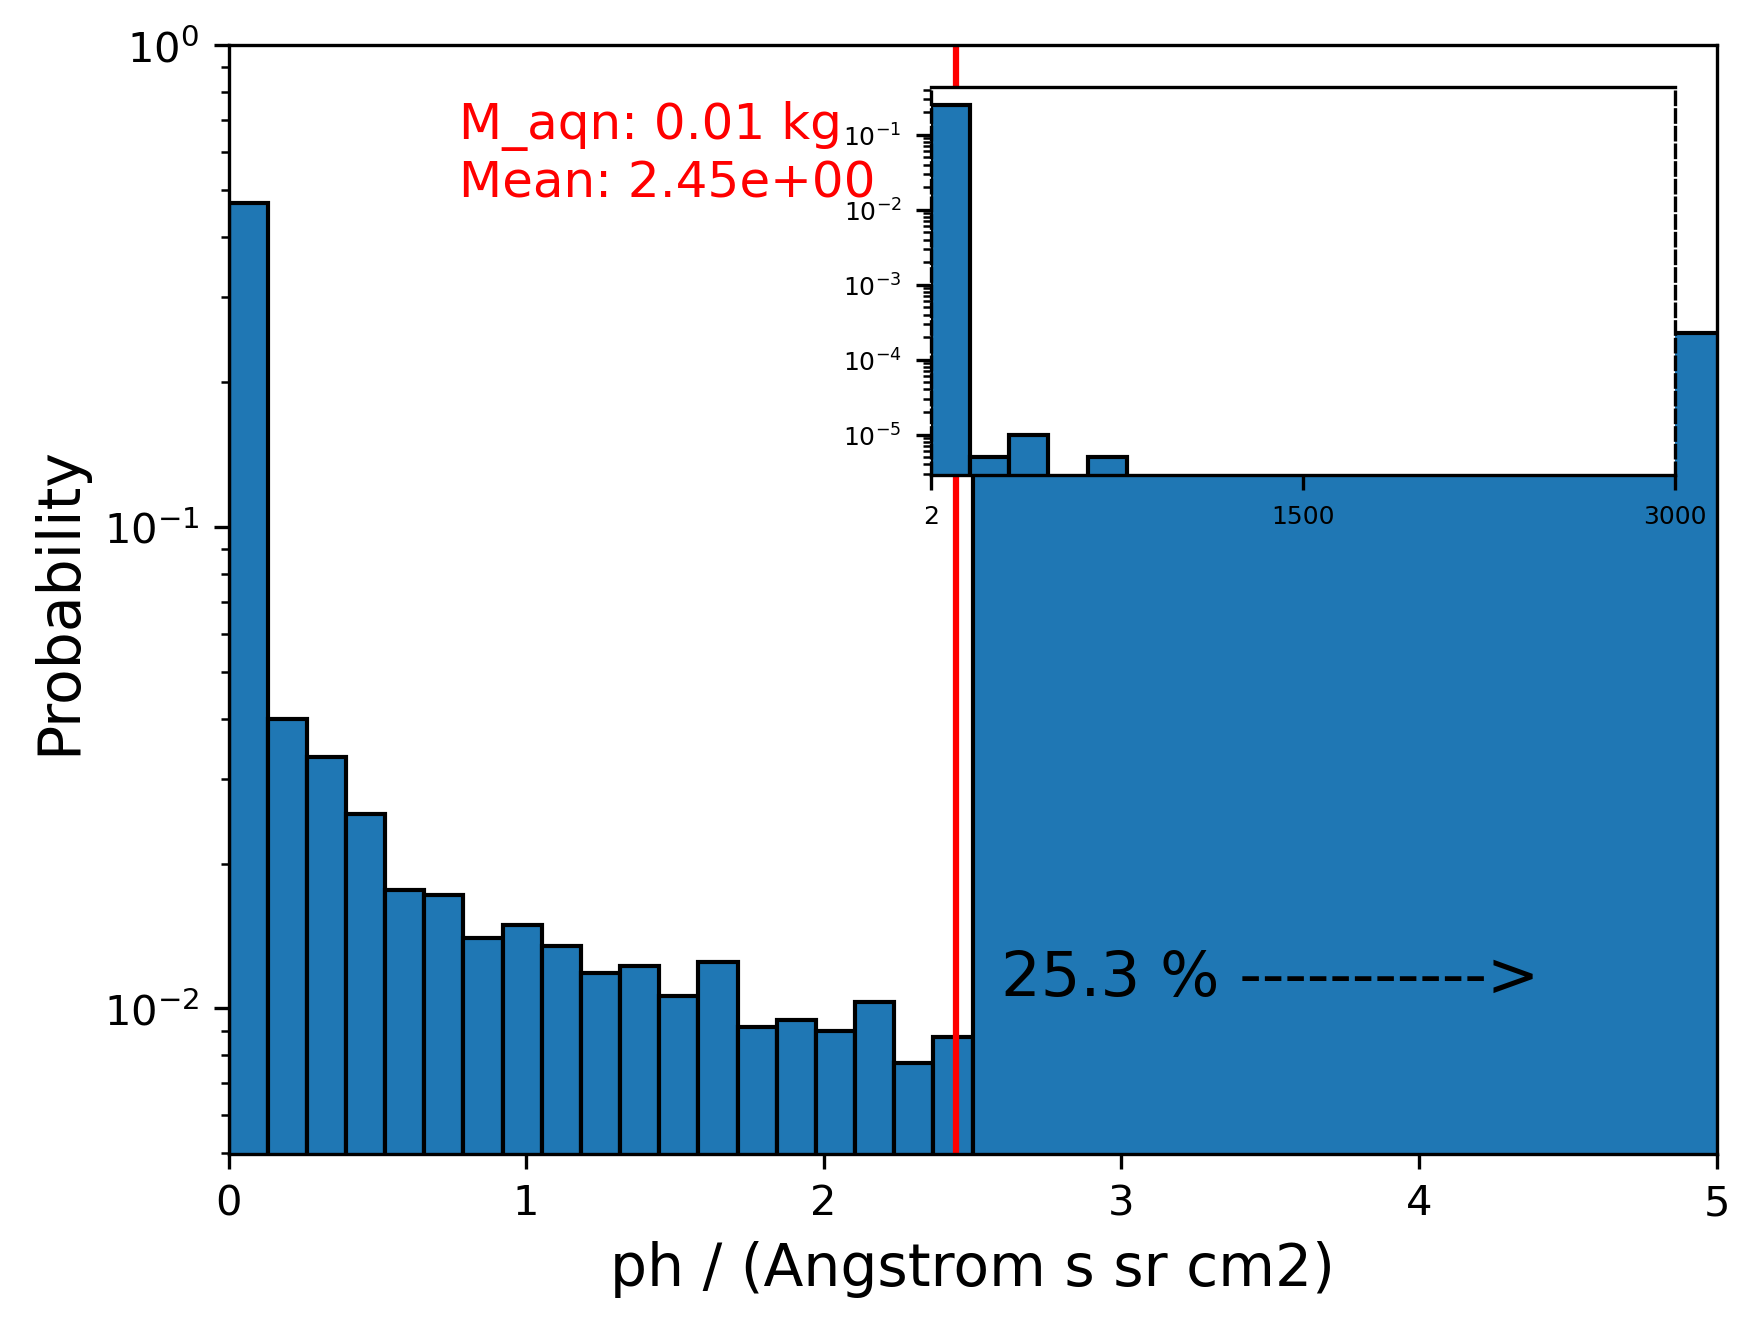

In [55]:
quant = cubes_m_0_01kg.copy()

to_photon_units = (0.6*u.kpc).to(u.cm)/(4*np.pi)
signal = quant["aqn_emit"] * to_photon_units
unit   = signal.unit


low_bins = np.linspace(0, 2.5, 20)  
high_bins = np.linspace(2.5, 3e3, 2)                    
bins = np.unique(np.concatenate((low_bins, high_bins)))  
low_end = np.where(bins==high_bins[0])[0][0]
# print(low_end[0][0])
res = np.histogram(signal.value, bins=bins)
counts = res[0] 
bin_widths = np.diff(res[1])  # Bin widths
probabilities = counts / len(signal)  # Fraction of total points in each bin

plt.figure(dpi=300)
plt.bar(res[1][:-1], probabilities, width=bin_widths, align='edge', edgecolor='k')

# # Annotate the probabilities on each bar
for k in range(len(probabilities)):
    if k == low_end:
        bin_center = res[1][k] #+ res[1][k + 1]) / 2
        plt.text(3.5, 1e-2, f'{probabilities[k]*100:.1f} % ----------->', #f'{probabilities[k]*100:.1e} %', 
                 ha='center', va='bottom', fontsize=15, rotation=0)



mean_signal = np.mean(signal.value)

plt.vlines(mean_signal, 0, np.max(probabilities)*100, color="red")

# # Set scale and labels
# plt.xscale("log")
plt.yscale("log")
plt.ylabel("Probability", size=14)
plt.xlabel(unit, size=14)
# plt.xlabel(key + " [" + str(unit) + "]", size=14)
plt.ylim([0,1])
plt.xlim([0,5])


plt.text(0.155, 0.95, f"M_aqn: 0.01 kg\nMean: {mean_signal:.2e}", transform=plt.gca().transAxes, 
         fontsize=12, verticalalignment='top', color="red")


# === Inset axis for the second range ===
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
res = np.histogram(signal.value, bins = np.linspace(2.5, 3e3, 20))
counts = res[0]  # Raw counts per bin
print(np.sum(counts))

bin_widths = np.diff(res[1])  # Bin widths
probabilities = counts / len(signal)  # Fraction of total points in each bin

# Create inset
ax_inset = inset_axes(plt.gca(), width="50%", height="35%", loc="upper right",  borderpad=1)
ax_inset.bar(res[1][:-1], probabilities, width=bin_widths, align='edge', edgecolor='k')
# ax_inset.set_xscale("log")
ax_inset.set_xlim([2.5, 3e3])  # Second range
ax_inset.set_yscale("log")
ax_inset.set_xticks([2.5, 1500, 3e3])  # Add ticks for clarity
ax_inset.tick_params(labelsize=6)

# Draw break lines (optional visual cue)
plt.gca().spines['right'].set_linestyle("--")
ax_inset.spines['left'].set_linestyle("--")


# # Save and show plot
plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-m-0_01kg.png", bbox_inches="tight")
plt.show()


In [ ]:
counts
m_aqn = "0.5"
savename = "all-regions-histogram-aqn-emit-R-1_6kpc-m-0_5kg-CC.png"

In [ ]:
def plot_aqn_histogram_cumulative(fig, ax, color, quant, m_aqn, high_low_cutoff, xlimmax, savename):
    to_photon_units = (0.6*u.kpc).to(u.cm)/(4*np.pi)
    signal = quant["aqn_emit"] * to_photon_units
    unit   = signal.unit
    
    max_signal = np.max(signal.value)
    
    print(f'Maximum value is {max_signal}')
    
    low_bins = np.linspace(0, high_low_cutoff, 20)  
    high_bins = np.linspace(high_low_cutoff, max_signal, 2)  
    bins = np.unique(np.concatenate((low_bins, high_bins)))  
    bins = np.linspace(0,xlimmax,50000)

    # low_end = np.where(bins==high_bins[0])[0][0]
    
    res = np.histogram(signal.value, bins=bins)
    indices = np.digitize(signal.value, bins)
    
    counts = res[0] 
    bin_widths = np.diff(res[1])  # Bin widths
    probabilities = 1 - np.cumsum(counts) / len(signal)  # Fraction of total points in each bin
    
    # plt.figure(dpi=300)
    # ax.bar(res[1][:-1], probabilities, width=bin_widths, align='edge', edgecolor='k')
    ax.step(res[1][:-1], probabilities, where='post', lw=2, label=m_aqn+" kg", c=color)

    # Annotate the probabilities on each bar
    # for k in range(len(probabilities)):
    #     if k == low_end:
    #         bin_center = res[1][k] #+ res[1][k + 1]) / 2
    #         plt.text((high_low_cutoff+xlimmax)/2, 1e-2, f'{probabilities[k]*100:.1f} % --->', #f'{probabilities[k]*100:.1e} %', 
    #                  ha='center', va='bottom', fontsize=12, rotation=0)

    # Annotate each bar with the average of values in `quant["ioni_gas"]`
    # for k in range(len(res[1]) - 1):  # Iterate over bins
    #     # Get indices of values in this bin
    #     bin_indices = np.where(indices == k + 1)[0]  # digitize returns 1-based bin index
    #     if len(bin_indices) > 0:
    #         avg_ioni_gas = quant["ioni_gas"][bin_indices].mean()
    #         bin_center = (res[1][k] + res[1][k + 1]) / 2
    #         if bin_center < high_low_cutoff:
    #             plt.text(bin_center, 1e-2, #(probabilities[k])/5 + 1e-2, 
    #                      f'{avg_ioni_gas:.2e}', ha='center', va='bottom', fontsize=8, rotation=90)
    
    mean_signal = np.mean(signal.value)
    
    # ax.vlines(mean_signal, 0, 1, color=color)
    # ax.vlines(150, 0, 0.6, color="blue")
    ax.grid(True, linestyle='--')
    
    # Add a horizontal band from y=100 to y=200 with light blue color
    ax.axvspan(100, 200, color='lightblue', alpha=0.5)
    # # Set scale and labels
    # plt.xscale("log")
    ax.set_xscale("log")
    ax.set_ylabel(r"$P(>\langle\Phi\rangle$)", size=14)
    ax.set_xlabel(r"$\langle\Phi\rangle$  " + "["+str(unit)+"]", size=14)
    ax.set_xlim(1,1e3)
    # ax.set_ylim([0,1])
    # ax.set_xlim([0,xlimmax])
    
    
    # ax.text(0.05, 0.9, f"M_aqn: {m_aqn} kg\nMean: {mean_signal:.2e}", transform=plt.gca().transAxes, 
    #          fontsize=12, verticalalignment='top', color="red",
    #         bbox=dict(facecolor='white', edgecolor='none', boxstyle='round,pad=0.3'))
    
    
    # # === Inset axis for the second range ===
    # from mpl_toolkits.axes_grid1.inset_locator import inset_axes
    # res = np.histogram(signal.value, bins = np.linspace(high_low_cutoff, max_signal, 20))
    # counts = res[0]  # Raw counts per bin
    # print(np.sum(counts))
    
    # bin_widths = np.diff(res[1])  # Bin widths
    # probabilities = counts / len(signal)  # Fraction of total points in each bin
    
    # # Create inset
    # ax_inset = inset_axes(plt.gca(), width="50%", height="35%", loc="upper right",  borderpad=1)
    # ax_inset.bar(res[1][:-1], probabilities, width=bin_widths, align='edge', edgecolor='k')
    # # ax_inset.set_xscale("log")
    # largest_nonzero_index = np.max(np.where(counts > 0)[0])
    # ax_inset.set_xlim([high_low_cutoff, max_signal])  # Second range
    # ax_inset.set_yscale("log")
    # ax_inset.set_xticks([high_low_cutoff, np.mean([high_low_cutoff, max_signal]), max_signal])  # Add ticks for clarity
    # ax_inset.tick_params(labelsize=6)
    
    # # Draw break lines (optional visual cue)
    # plt.gca().spines['right'].set_linestyle("--")
    # ax_inset.spines['left'].set_linestyle("--")
    
    
    # # Save and show plot
    # ax.savefig("../visuals/"+savename, bbox_inches="tight")
    # plt.show()

In [ ]:
def plot_aqn_histogram_cumulative(fig, ax, linetype, quant, m_aqn, xlimmax):
    to_photon_units = (0.6*u.kpc).to(u.cm)/(4*np.pi)
    signal = quant["aqn_emit"] * to_photon_units
    unit   = signal.unit
    
    max_signal = np.max(signal.value)
    
    print(f'Maximum value is {max_signal}')
    
    # low_bins = np.linspace(0, high_low_cutoff, 20)  
    # high_bins = np.linspace(high_low_cutoff, max_signal, 2)  
    # bins = np.unique(np.concatenate((low_bins, high_bins)))  
    bins = np.linspace(0,xlimmax,50000)
    # bins = np.logspace(-80,3,5000)

    # low_end = np.where(bins==high_bins[0])[0][0]
    
    res = np.histogram(signal.value, bins=bins)
    indices = np.digitize(signal.value, bins)
    
    counts = res[0] 
    bin_widths = np.diff(res[1])  # Bin widths
    probabilities = 1 - np.cumsum(counts) / len(signal)  # Fraction of total points in each bin
    
    # plt.figure(dpi=300)
    # ax.bar(res[1][:-1], probabilities, width=bin_widths, align='edge', edgecolor='k')
    ax.step(res[1][:-1], probabilities, where='post', lw=2, label=m_aqn+" kg", linestyle=linetype)

    # Annotate the probabilities on each bar
    # for k in range(len(probabilities)):
    #     if k == low_end:
    #         bin_center = res[1][k] #+ res[1][k + 1]) / 2
    #         plt.text((high_low_cutoff+xlimmax)/2, 1e-2, f'{probabilities[k]*100:.1f} % --->', #f'{probabilities[k]*100:.1e} %', 
    #                  ha='center', va='bottom', fontsize=12, rotation=0)

    # Annotate each bar with the average of values in `quant["ioni_gas"]`
    # for k in range(len(res[1]) - 1):  # Iterate over bins
    #     # Get indices of values in this bin
    #     bin_indices = np.where(indices == k + 1)[0]  # digitize returns 1-based bin index
    #     if len(bin_indices) > 0:
    #         avg_ioni_gas = quant["ioni_gas"][bin_indices].mean()
    #         bin_center = (res[1][k] + res[1][k + 1]) / 2
    #         if bin_center < high_low_cutoff:
    #             plt.text(bin_center, 1e-2, #(probabilities[k])/5 + 1e-2, 
    #                      f'{avg_ioni_gas:.2e}', ha='center', va='bottom', fontsize=8, rotation=90)
    
    mean_signal = np.mean(signal.value)
    
    # ax.vlines(mean_signal, 0, 1, color=color)
    # ax.vlines(150, 0, 0.6, color="blue")
    # ax.grid(True, linestyle='--', which="both")
    
    # Add a horizontal band from y=100 to y=200 with light blue color
    ax.axvspan(100, 200, color='lightblue', alpha=0.5)
    # # Set scale and labels
    # plt.xscale("log")
    ax.set_xscale("log")
    ax.set_xlim(1e0,xlimmax)
    # ax.set_ylim([0,1])
    # ax.set_xlim([0,xlimmax])



In [ ]:
plt.close()
fig, ax = plt.subplots(dpi=300)

xlimmax = 1000

# plot_aqn_histogram_cumulative(fig, ax, "#CC0000", cubes_m_0_5kg.copy(), "0.5", high_low_cutoff = 1500, xlimmax=xlimmax, 
#                    savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_5kg-CC-cum.png")
# plot_aqn_histogram_cumulative(fig, ax, "#FF6666", cubes_m_0_1kg.copy(), "0.1", high_low_cutoff = 700, xlimmax=xlimmax, 
#                    savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_1kg-CC.png")
# plot_aqn_histogram_cumulative(fig, ax, "#FFB3B3", cubes_m_0_01kg.copy(), "0.01", high_low_cutoff = 30, xlimmax=xlimmax, 
#                    savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_01kg-CC-cum.png")

# plot_aqn_histogram_cumulative(fig, ax, "-", cubes_m_0_5kg.copy(), "0.5", high_low_cutoff = 1500, xlimmax=xlimmax, 
#                    savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_5kg-CC-cum.png")

plot_aqn_histogram_cumulative(fig, ax, "-", cubes_m_0_5kg.copy(), "0.5", xlimmax=xlimmax)
plot_aqn_histogram_cumulative(fig, ax, "--", cubes_m_0_1kg.copy(), "0.1", xlimmax=xlimmax)
plot_aqn_histogram_cumulative(fig, ax, "-.", cubes_m_0_01kg.copy(), "0.01", xlimmax=xlimmax)
# plot_aqn_histogram_cumulative(fig, ax, "-", cubes_m_0_5kg_no_mod_n_ion.copy(), "0.5", xlimmax=xlimmax)

plt.legend(fontsize=14)
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.png", bbox_inches="tight")
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.pdf", bbox_inches="tight")
plt.show()

In [76]:
# final_aqn_signal[0.5]

In [ ]:
# version with the summing correctly implemented
plt.close()
fig, ax = plt.subplots(1,3, dpi=400, figsize=(9,3), sharey=True)

xlimmax = 1000

to_photon_units = (0.6*u.kpc).to(u.cm)/(4*np.pi)
# signal = cubes_m_0_5kg["aqn_emit"] * to_photon_units
# unit   = signal.unit
unit = final_aqn_signal[0.5].unit

plot_aqn_histogram_cumulative_updated(fig, ax[0], "-", final_aqn_signal[0.5].copy(), "0.5", xlimmax=xlimmax)
plot_aqn_histogram_cumulative_updated(fig, ax[0], "--", final_aqn_signal[0.1].copy(), "0.1", xlimmax=xlimmax)
plot_aqn_histogram_cumulative_updated(fig, ax[0], "-.", final_aqn_signal[0.01].copy(), "0.01", xlimmax=xlimmax)

plot_aqn_histogram_cumulative_updated(fig, ax[2], "-", final_aqn_signal_FIRE_dv[0.5].copy(), "0.5", xlimmax=xlimmax)
plot_aqn_histogram_cumulative_updated(fig, ax[2], "--", final_aqn_signal_FIRE_dv[0.1].copy(), "0.1", xlimmax=xlimmax)
plot_aqn_histogram_cumulative_updated(fig, ax[2], "-.", final_aqn_signal_FIRE_dv[0.01].copy(), "0.01", xlimmax=xlimmax)

ax[1].set_xlabel(r"AQN Annihilation FUV Signal, $\langle\Phi_\lambda\rangle$  " + "["+str(unit)+"]", size=14)
ax[0].set_ylabel(r"P$(>\langle\Phi_\lambda\rangle)$", size=14)

# import matplotlib.ticker as ticker
# ax[0].xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=[0.1, 0.3, 0.5, 0.7], numticks=10))
# ax[0].grid(True, linestyle='--', which="minor")

for i in [0,1,2]:
    ax[i].grid(True, linestyle="--", which="major", lw=0.5)
    minor_ticks = ax[i].xaxis.get_minor_locator().tick_values(1e0, 1e3)  # Adjust range as needed
    selected_minor_ticks = minor_ticks[::2]  # Select every second minor tick
    for tick in selected_minor_ticks:
        ax[i].axvline(tick, color='gray', linestyle='--', alpha=0.5, linewidth=0.5)  # Adjust appearance as needed

plt.legend(loc="upper left", fontsize=12, title="AQN Mass", title_fontsize=12, bbox_to_anchor=(0, 0.88))

plt.subplots_adjust(wspace=0.11, hspace=0)
ax[0].text(0.5, 1, f"Final estimate", ha='center', va='bottom', transform=ax[0].transAxes, fontsize=14)
ax[1].text(0.5, 1, r"Unscaled n$_{\text{ion}}$", ha='center', va='bottom', transform=ax[1].transAxes, fontsize=14)
ax[2].text(0.5, 1, r"$\Delta v$ from m12i", ha='center', va='bottom', transform=ax[2].transAxes, fontsize=14)

# ax[0].set_title("test", fontsize=15)
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.png", bbox_inches="tight")
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.pdf", bbox_inches="tight")

# plt.savefig("../visuals/final-AQN-signal-plot-april-12.pdf", bbox_inches="tight")
plt.show()


## Final Plot of AQN Signal

(281,)
Maximum value is 1244.7363634836345
(281,)
Maximum value is 232.88468123937898
(290,)
Maximum value is 18.237795157989318
(281,)
Maximum value is 144005.75266811874
(281,)
Maximum value is 27747.682513092488
(281,)
Maximum value is 2253.190451226069


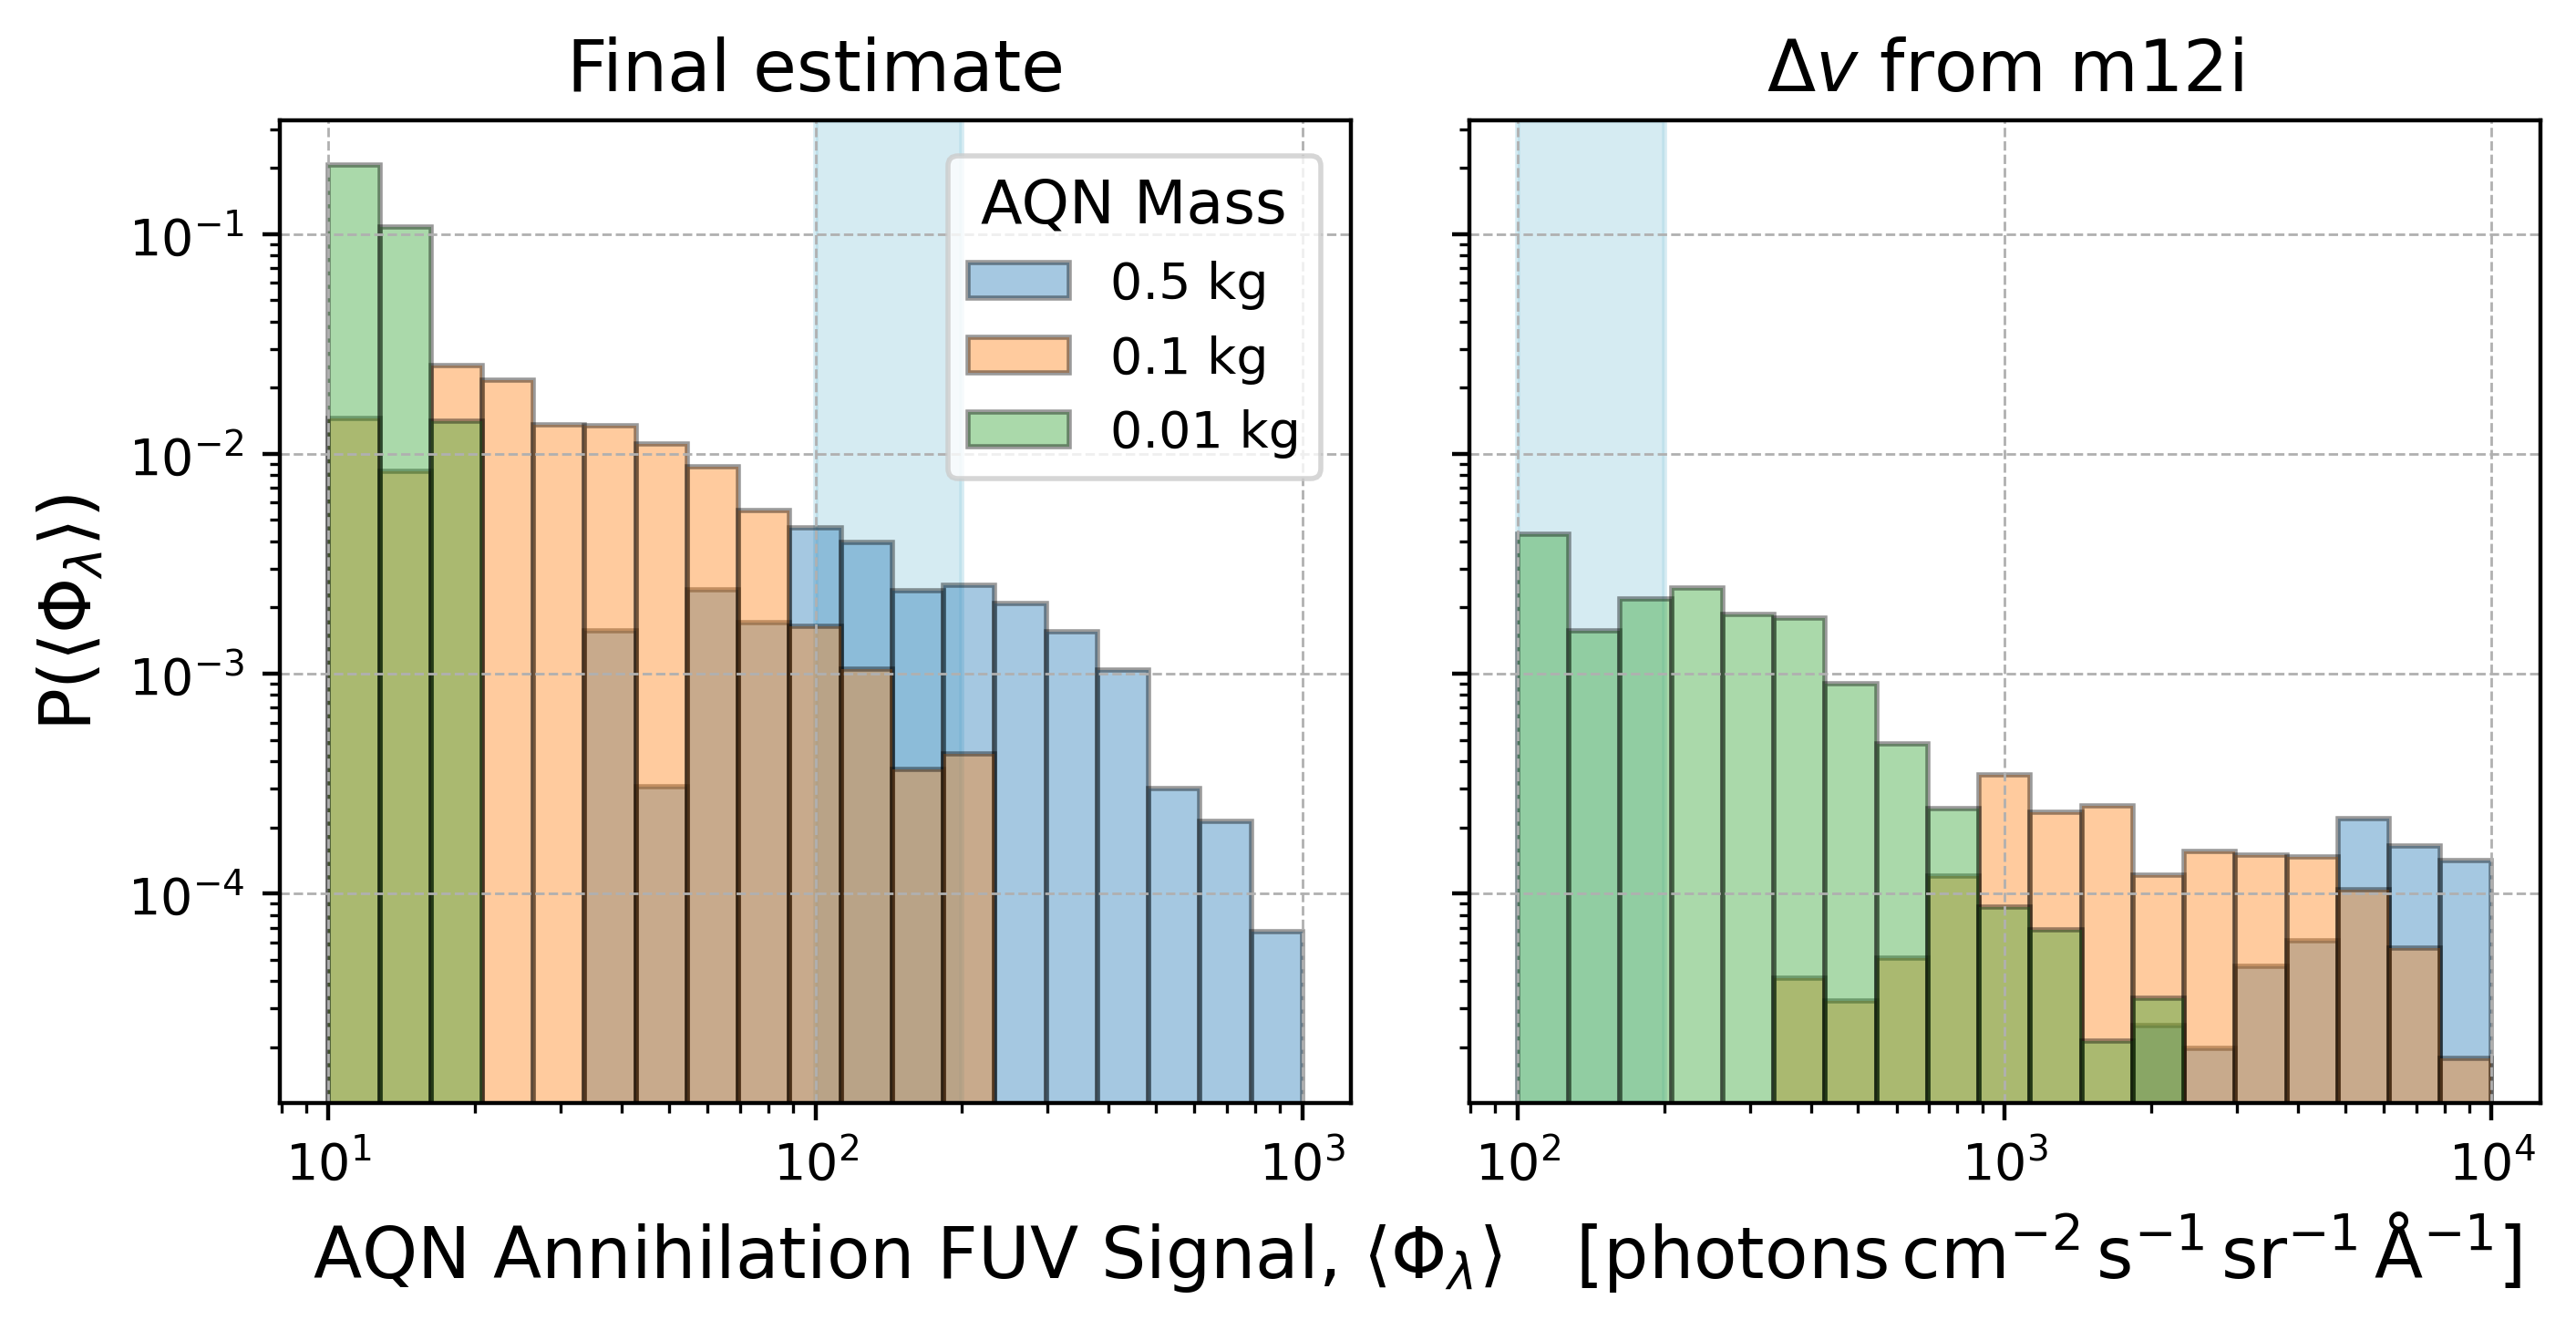

In [89]:
# version with the summing correctly implemented
plt.close()
fig, ax = plt.subplots(1,2, dpi=400, figsize=(8,3.5), sharey=True)

xlimmax = 1000

to_photon_units = (0.6*u.kpc).to(u.cm)/(4*np.pi)
# signal = cubes_m_0_5kg["aqn_emit"] * to_photon_units
# unit   = signal.unit
# unit = final_aqn_signal[0.5].unit
unit = photon_units

ax[0].axvspan(100, 200, color='lightblue', alpha=0.5)    
ax[1].axvspan(100, 200, color='lightblue', alpha=0.5)    



bins_to_use = np.logspace(1,3,20)

plot_aqn_histogram_updated(fig, ax[0], "-",  final_aqn_signal[0.5].copy(), "0.5", bins = bins_to_use, color="blue")
plot_aqn_histogram_updated(fig, ax[0], "--", final_aqn_signal[0.1].copy(), "0.1", bins = bins_to_use, color="orange")
plot_aqn_histogram_updated(fig, ax[0], "-.", final_aqn_signal[0.01].copy(), "0.01", bins = bins_to_use, color="green")

bins_to_use = np.logspace(2,4,20)

plot_aqn_histogram_updated(fig, ax[1], "-",  final_aqn_signal_FIRE_dv[0.5].copy(), "0.5", bins = bins_to_use, color="blue")
plot_aqn_histogram_updated(fig, ax[1], "--", final_aqn_signal_FIRE_dv[0.1].copy(), "0.1", bins = bins_to_use, color="orange")
plot_aqn_histogram_updated(fig, ax[1], "-.", final_aqn_signal_FIRE_dv[0.01].copy(), "0.01", bins = bins_to_use, color="green")



ax[0].set_ylabel(r"P$(\langle\Phi_\lambda\rangle)$", size=14)

for i in [0,1]:
    ax[i].grid(True, linestyle="--", which="major", lw=0.5)
    # minor_ticks = ax[i].xaxis.get_minor_locator().tick_values(1e2, 1e2)  # Adjust range as needed
    # selected_minor_ticks = minor_ticks[::4]  # Select every second minor tick
    # for tick in selected_minor_ticks:
    #     ax[i].axvline(tick, color='gray', linestyle='--', alpha=0.5, linewidth=0.5)  # Adjust appearance as needed

ax[0].legend(loc="upper left", fontsize=10, title="AQN Mass", title_fontsize=12, bbox_to_anchor=(0.6, 0.99))

plt.subplots_adjust(wspace=0.11, hspace=0)
# ax[0].text(0.5, 1, f"Final estimate", ha='center', va='bottom', transform=ax[0].transAxes, fontsize=14)
# ax[1].text(0.5, 1, r"$\Delta v$ from m12i", ha='center', va='bottom', transform=ax[0].transAxes, fontsize=14)

# ax[0].text(1e1,1e-4,r"AQN Annihilation FUV Signal, $\langle\Phi_\lambda\rangle$  " + "["+str(unit)+"]", fontsize=14)

ax[0].text(0.93e1,0.18e-5, r"AQN Annihilation FUV Signal, $\langle\Phi_\lambda\rangle \quad [\mathrm{photons}\,\mathrm{cm}^{-2}\,\mathrm{s}^{-1}\,\mathrm{sr}^{-1}\,\mathrm{\AA}^{-1}]$", fontsize=14)

ax[0].set_title(f"Final estimate", fontsize=14)
ax[1].set_title(r"$\Delta v$ from m12i", fontsize=14)

# ax[1].set_xlim([1e2-10,1e4+1000])
# ax[0].set_xlim([1e1-1,1e3+100])
# ax[0].set_title("test", fontsize=15)
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.png", bbox_inches="tight")
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.pdf", bbox_inches="tight")

# plt.savefig("../visuals/final-AQN-signal-hist-oct-16.pdf", bbox_inches="tight")
plt.show()


Maximum value is 1244.7363634836345
Maximum value is 232.88468123937898
Maximum value is 18.237795157989318
Maximum value is 144005.75266811874
Maximum value is 27747.682513092488
Maximum value is 2253.190451226069


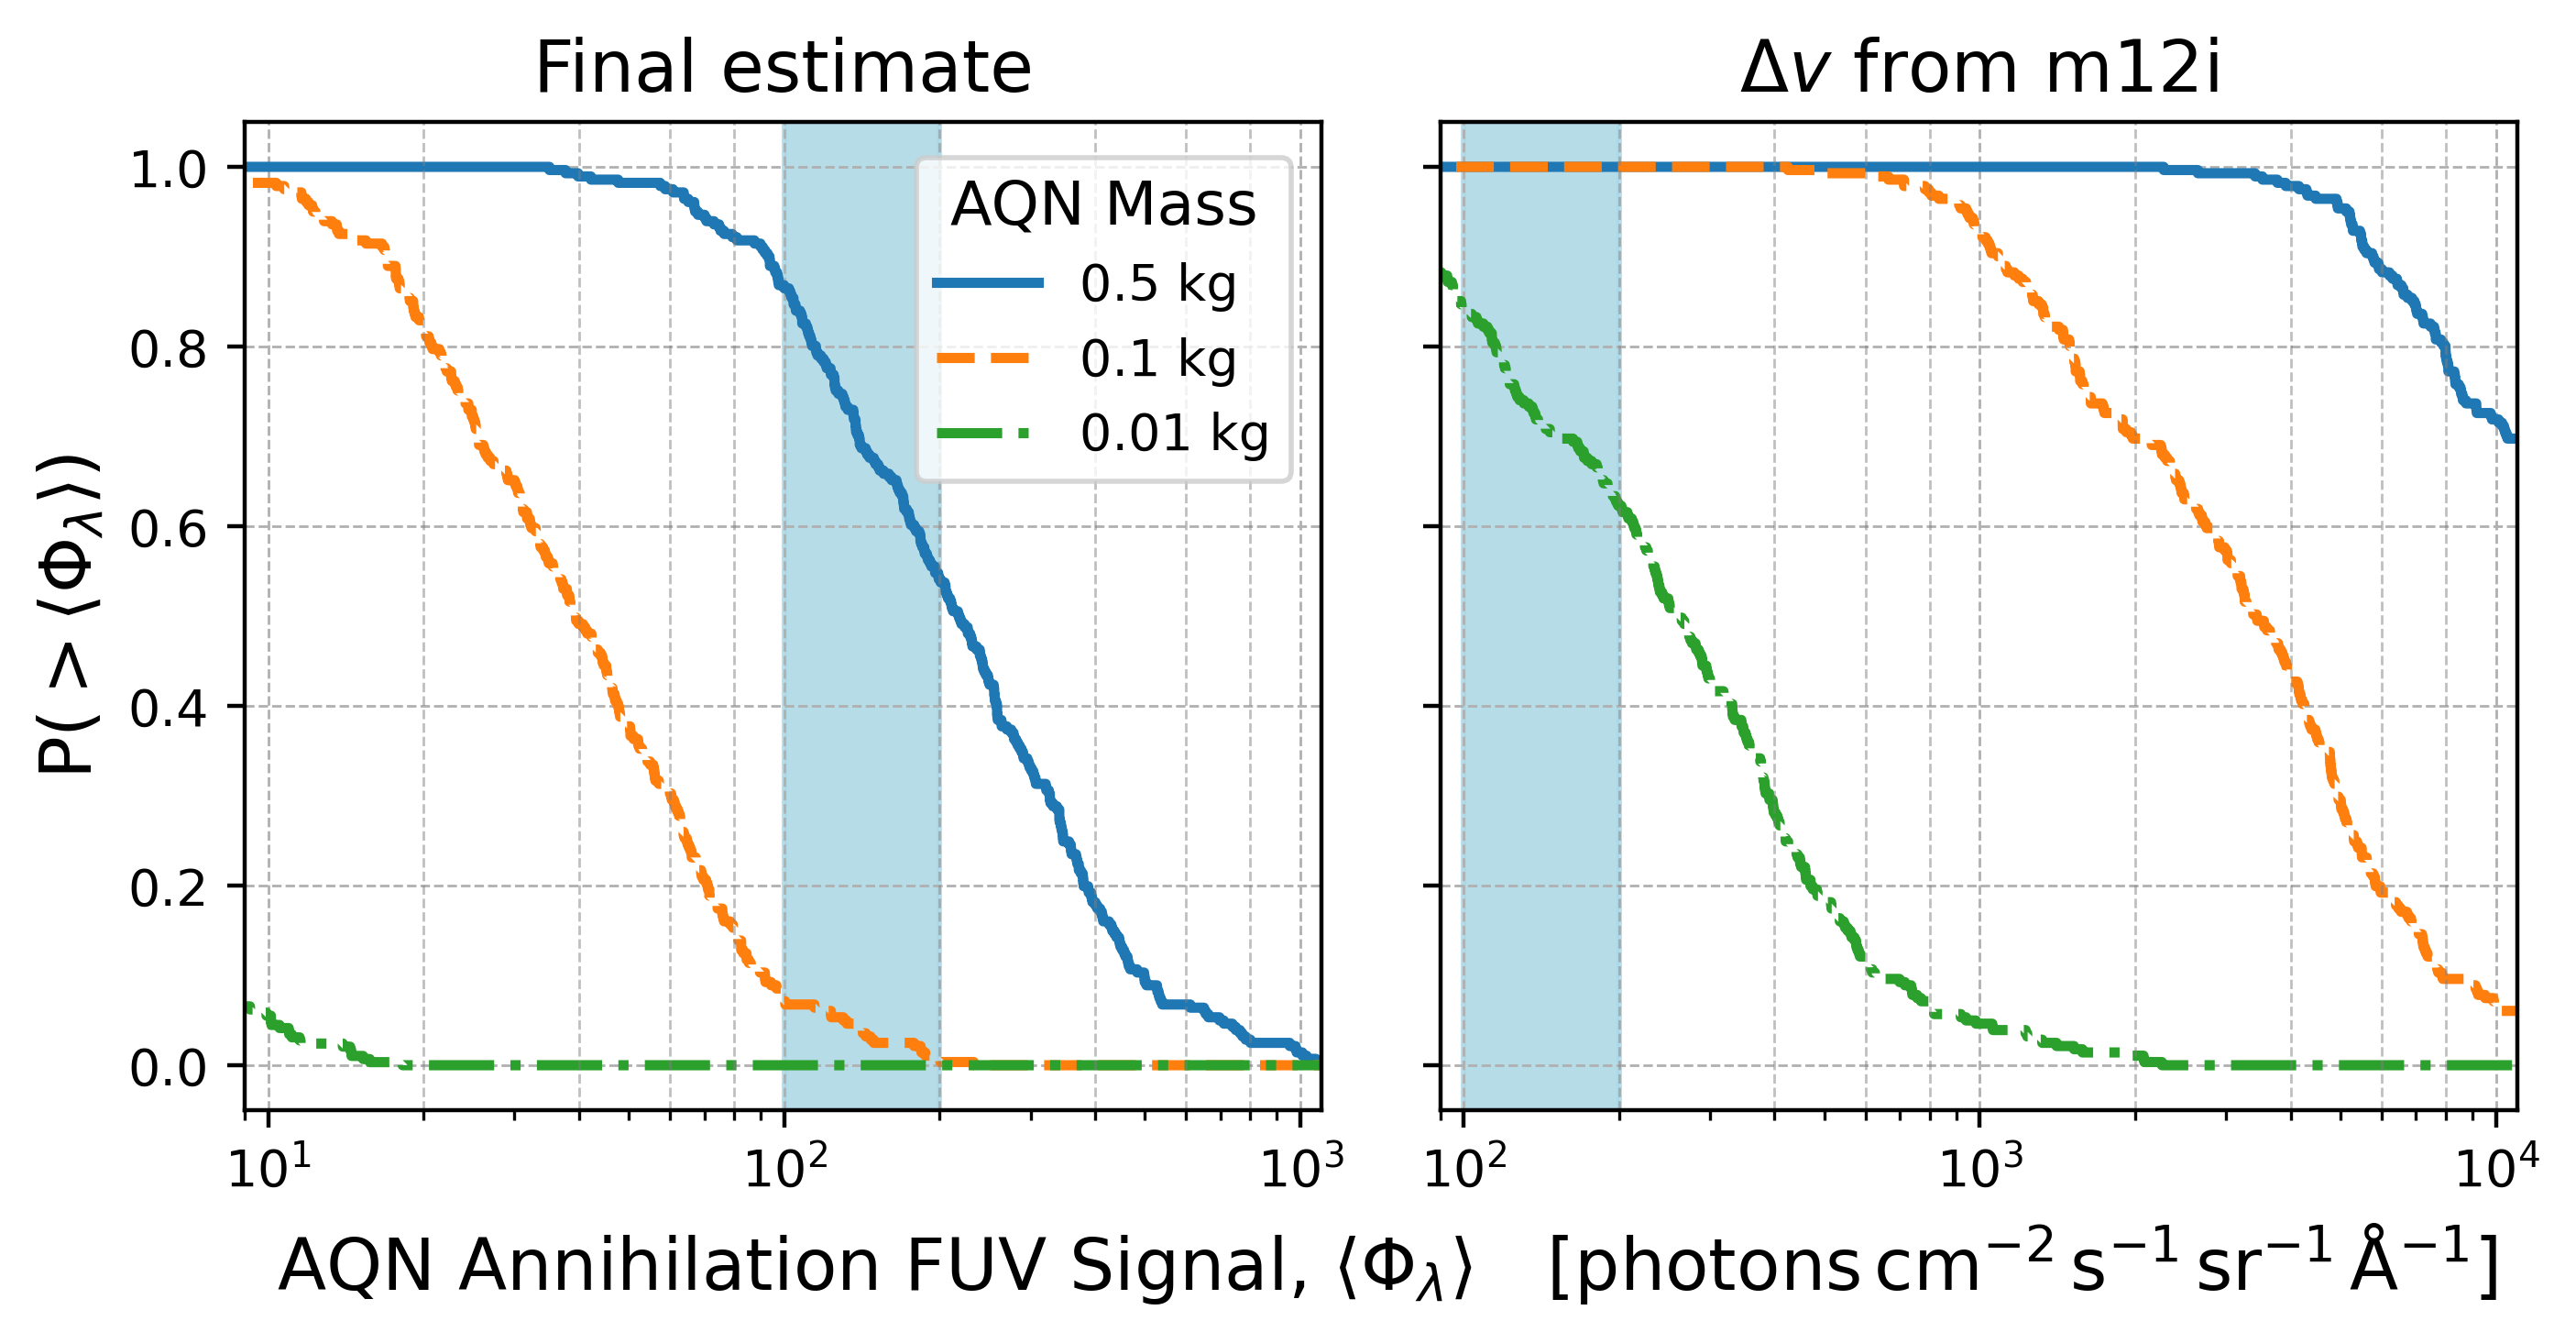

In [174]:
# version with the summing correctly implemented
plt.close()
fig, ax = plt.subplots(1,2, dpi=400, figsize=(8,3.5), sharey=True)

xlimmax = 1000

to_photon_units = (0.6*u.kpc).to(u.cm)/(4*np.pi)
# signal = cubes_m_0_5kg["aqn_emit"] * to_photon_units
# unit   = signal.unit
unit = final_aqn_signal[0.5].unit

plot_aqn_histogram_cumulative_updated(fig, ax[0], "-", final_aqn_signal[0.5].copy(), "0.5", xlimmax=xlimmax+100)
plot_aqn_histogram_cumulative_updated(fig, ax[0], "--", final_aqn_signal[0.1].copy(), "0.1", xlimmax=xlimmax+100)
plot_aqn_histogram_cumulative_updated(fig, ax[0], "-.", final_aqn_signal[0.01].copy(), "0.01", xlimmax=xlimmax+100)

plot_aqn_histogram_cumulative_updated(fig, ax[1], "-", final_aqn_signal_FIRE_dv[0.5].copy(), "0.5", xlimmax=1e4+1000)
plot_aqn_histogram_cumulative_updated(fig, ax[1], "--", final_aqn_signal_FIRE_dv[0.1].copy(), "0.1", xlimmax=1e4+1000)
plot_aqn_histogram_cumulative_updated(fig, ax[1], "-.", final_aqn_signal_FIRE_dv[0.01].copy(), "0.01", xlimmax=1e4+1000)

ax[0].set_ylabel(r"P$(>\langle\Phi_\lambda\rangle)$", size=14)

# import matplotlib.ticker as ticker
# ax[0].xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=[0.1, 0.3, 0.5, 0.7], numticks=10))
# ax[0].grid(True, linestyle='--', which="minor")

for i in [0,1]:
    ax[i].grid(True, linestyle="--", which="major", lw=0.5)
    minor_ticks = ax[i].xaxis.get_minor_locator().tick_values(1e0, 1e3)  # Adjust range as needed
    selected_minor_ticks = minor_ticks[::2]  # Select every second minor tick
    for tick in selected_minor_ticks:
        ax[i].axvline(tick, color='gray', linestyle='--', alpha=0.5, linewidth=0.5)  # Adjust appearance as needed

ax[0].legend(loc="upper left", fontsize=10, title="AQN Mass", title_fontsize=12, bbox_to_anchor=(0.6, 0.99))

plt.subplots_adjust(wspace=0.11, hspace=0)
# ax[0].text(0.5, 1, f"Final estimate", ha='center', va='bottom', transform=ax[0].transAxes, fontsize=14)
# ax[1].text(0.5, 1, r"$\Delta v$ from m12i", ha='center', va='bottom', transform=ax[0].transAxes, fontsize=14)

# ax[0].text(12.5,-0.25,r"AQN Annihilation FUV Signal, $\langle\Phi_\lambda\rangle$  " + "["+str(unit)+"]", fontsize=14)
ax[0].text(10.4,-0.25, r"AQN Annihilation FUV Signal, $\langle\Phi_\lambda\rangle \quad [\mathrm{photons}\,\mathrm{cm}^{-2}\,\mathrm{s}^{-1}\,\mathrm{sr}^{-1}\,\mathrm{\AA}^{-1}]$", fontsize=14)


ax[0].set_title(f"Final estimate", fontsize=14)
ax[1].set_title(r"$\Delta v$ from m12i", fontsize=14)

ax[1].set_xlim([1e2-10,1e4+1000])
ax[0].set_xlim([1e1-1,1e3+100])
# ax[0].set_title("test", fontsize=15)
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.png", bbox_inches="tight")
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.pdf", bbox_inches="tight")

plt.savefig("../visuals/final-AQN-signal-plot-oct-15.pdf", bbox_inches="tight")
plt.show()


In [ ]:
# version with the summing correctly implemented
plt.close()
fig, ax = plt.subplots(1,1, dpi=400, figsize=(3.74,3.74), sharey=True)

ax = [ax]

xlimmax = 1000

to_photon_units = (0.6*u.kpc).to(u.cm)/(4*np.pi)
# signal = cubes_m_0_5kg["aqn_emit"] * to_photon_units
# unit   = signal.unit
unit = final_aqn_signal[0.5].unit

plot_aqn_histogram_cumulative_updated(fig, ax[0], "-", final_aqn_signal[0.5].copy(), "0.5", xlimmax=xlimmax+100)
plot_aqn_histogram_cumulative_updated(fig, ax[0], "--", final_aqn_signal[0.1].copy(), "0.1", xlimmax=xlimmax+100)
plot_aqn_histogram_cumulative_updated(fig, ax[0], "-.", final_aqn_signal[0.01].copy(), "0.01", xlimmax=xlimmax+100)

# plot_aqn_histogram_cumulative_updated(fig, ax[1], "-", final_aqn_signal_FIRE_dv[0.5].copy(), "0.5", xlimmax=1e4+1000)
# plot_aqn_histogram_cumulative_updated(fig, ax[1], "--", final_aqn_signal_FIRE_dv[0.1].copy(), "0.1", xlimmax=1e4+1000)
# plot_aqn_histogram_cumulative_updated(fig, ax[1], "-.", final_aqn_signal_FIRE_dv[0.01].copy(), "0.01", xlimmax=1e4+1000)

ax[0].set_ylabel(r"P$(>\langle\Phi_\lambda\rangle)$", size=14)

# import matplotlib.ticker as ticker
# ax[0].xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=[0.1, 0.3, 0.5, 0.7], numticks=10))
# ax[0].grid(True, linestyle='--', which="minor")

for i in [0]:
    ax[i].grid(True, linestyle="--", which="major", lw=0.5)
    minor_ticks = ax[i].xaxis.get_minor_locator().tick_values(1e0, 1e3)  # Adjust range as needed
    selected_minor_ticks = minor_ticks[::2]  # Select every second minor tick
    for tick in selected_minor_ticks:
        ax[i].axvline(tick, color='gray', linestyle='--', alpha=0.5, linewidth=0.5)  # Adjust appearance as needed

ax[0].legend(loc="upper left", fontsize=10, title="AQN Mass", title_fontsize=12, bbox_to_anchor=(0.6, 0.99))
# ax[0].text(12.5,-0.25,)
ax[0].set_xlabel("AQN Annihilation FUV Signal"+r" $\langle\Phi_\lambda\rangle$" + "\n" + "["+str(unit)+"]", fontsize=14)
# ax[0].set_title(f"Final estimate", fontsize=14)
ax[0].set_xlim([1e1-1,1e3+100])


plt.savefig("../visuals/final-AQN-signal-plot-april-12-single-panel.pdf", bbox_inches="tight")
plt.show()


In [ ]:
plt.close()
fig, ax = plt.subplots(1,3, dpi=400, figsize=(9,3), sharey=True)

xlimmax = 1000

to_photon_units = (0.6*u.kpc).to(u.cm)/(4*np.pi)
signal = cubes_m_0_5kg["aqn_emit"] * to_photon_units
unit   = signal.unit

plot_aqn_histogram_cumulative(fig, ax[0], "-",  cubes_m_0_5kg.copy(), "0.5", xlimmax=xlimmax)
plot_aqn_histogram_cumulative(fig, ax[0], "--", cubes_m_0_1kg.copy(), "0.1", xlimmax=xlimmax)
plot_aqn_histogram_cumulative(fig, ax[0], "-.", cubes_m_0_01kg.copy(), "0.01", xlimmax=xlimmax)

# plot_aqn_histogram_cumulative(fig, ax[1], "-",  cubes_m_0_5kg_no_mod_n_ion.copy(), "0.5", xlimmax=xlimmax)
# plot_aqn_histogram_cumulative(fig, ax[1], "--", cubes_m_0_1kg_no_mod_n_ion.copy(), "0.1", xlimmax=xlimmax)
# plot_aqn_histogram_cumulative(fig, ax[1], "-.", cubes_m_0_01kg_no_mod_n_ion.copy(), "0.01", xlimmax=xlimmax)

plot_aqn_histogram_cumulative(fig, ax[2], "-",  cubes_m_0_5kg_FIRE_dv.copy(), "0.5", xlimmax=xlimmax)
plot_aqn_histogram_cumulative(fig, ax[2], "--", cubes_m_0_1kg_FIRE_dv.copy(), "0.1", xlimmax=xlimmax)
plot_aqn_histogram_cumulative(fig, ax[2], "-.", cubes_m_0_01kg_FIRE_dv.copy(), "0.01", xlimmax=xlimmax)

ax[1].set_xlabel(r"AQN Annihilation FUV Signal, $\langle\Phi_\lambda\rangle$  " + "["+str(unit)+"]", size=14)
ax[0].set_ylabel("Exceedance Probab.," "\n" r"P$(>\langle\Phi_\lambda\rangle)$", size=14)

# import matplotlib.ticker as ticker
# ax[0].xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=[0.1, 0.3, 0.5, 0.7], numticks=10))
# ax[0].grid(True, linestyle='--', which="minor")

for i in [0,1,2]:
    ax[i].grid(True, linestyle="--", which="major", lw=0.5)
    minor_ticks = ax[i].xaxis.get_minor_locator().tick_values(1e0, 1e3)  # Adjust range as needed
    selected_minor_ticks = minor_ticks[::2]  # Select every second minor tick
    for tick in selected_minor_ticks:
        ax[i].axvline(tick, color='gray', linestyle='--', alpha=0.5, linewidth=0.5)  # Adjust appearance as needed

plt.legend(loc="upper left", fontsize=12, title="AQN Mass", title_fontsize=12, bbox_to_anchor=(0, 0.88))

plt.subplots_adjust(wspace=0.11, hspace=0)
ax[0].text(0.5, 0.88, f"Final estimate", ha='center', va='bottom', transform=ax[0].transAxes, fontsize=14)
ax[1].text(0.5, 0.88, r"Unscaled n$_{\text{ion}}$", ha='center', va='bottom', transform=ax[1].transAxes, fontsize=14)
ax[2].text(0.5, 0.88, r"$\Delta v$ from m12i", ha='center', va='bottom', transform=ax[2].transAxes, fontsize=14)

# ax[0].set_title("test", fontsize=15)
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.png", bbox_inches="tight")
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.pdf", bbox_inches="tight")

# plt.savefig("../visuals/final-AQN-signal-plot.pdf", bbox_inches="tight")
plt.show()


In [ ]:
plt.close()
fig, ax = plt.subplots(3,1, dpi=400, figsize=(3,7), sharex=True)

xlimmax = 1000

to_photon_units = (0.6*u.kpc).to(u.cm)/(4*np.pi)
signal = cubes_m_0_5kg["aqn_emit"] * to_photon_units
unit   = signal.unit

plot_aqn_histogram_cumulative(fig, ax[0], "-",  cubes_m_0_5kg.copy(), "0.5", xlimmax=xlimmax)
plot_aqn_histogram_cumulative(fig, ax[0], "--", cubes_m_0_1kg.copy(), "0.1", xlimmax=xlimmax)
plot_aqn_histogram_cumulative(fig, ax[0], "-.", cubes_m_0_01kg.copy(), "0.01", xlimmax=xlimmax)

plot_aqn_histogram_cumulative(fig, ax[1], "-",  cubes_m_0_5kg_no_mod_n_ion.copy(), "0.5", xlimmax=xlimmax)
plot_aqn_histogram_cumulative(fig, ax[1], "--", cubes_m_0_1kg_no_mod_n_ion.copy(), "0.1", xlimmax=xlimmax)
plot_aqn_histogram_cumulative(fig, ax[1], "-.", cubes_m_0_01kg_no_mod_n_ion.copy(), "0.01", xlimmax=xlimmax)

plot_aqn_histogram_cumulative(fig, ax[2], "-",  cubes_m_0_5kg_FIRE_dv.copy(), "0.5", xlimmax=xlimmax)
plot_aqn_histogram_cumulative(fig, ax[2], "--", cubes_m_0_1kg_FIRE_dv.copy(), "0.1", xlimmax=xlimmax)
plot_aqn_histogram_cumulative(fig, ax[2], "-.", cubes_m_0_01kg_FIRE_dv.copy(), "0.01", xlimmax=xlimmax)

ax[2].set_xlabel(r"AQN Annihilation FUV Signal,"+"\n"+r"$\langle\Phi_\lambda\rangle$  " + "["+str(unit)+"]", size=14)
ax[1].set_ylabel("Exceedance Probab.,"+ r" P$(>\langle\Phi_\lambda\rangle)$", size=14)

# import matplotlib.ticker as ticker
# ax[0].xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=[0.1, 0.3, 0.5, 0.7], numticks=10))
# ax[0].grid(True, linestyle='--', which="minor")

for i in [0,1,2]:
    ax[i].grid(True, linestyle="--", which="major", lw=0.5)
    ax[i].set_yticks([0,0.1,0.2,0.3,0.4,0.5])
    minor_ticks = ax[i].xaxis.get_minor_locator().tick_values(1e0, 1e3)  # Adjust range as needed
    selected_minor_ticks = minor_ticks[::2]  # Select every second minor tick
    for tick in selected_minor_ticks:
        ax[i].axvline(tick, color='gray', linestyle='--', alpha=0.5, linewidth=0.5)  # Adjust appearance as needed

plt.legend(loc="upper left", fontsize=12, title="AQN Mass", title_fontsize=12)

ax[0].set_title(f"Final estimate", fontsize=14)
ax[1].set_title(r"Unscaled n$_{\text{ion}}$", fontsize=14)
ax[2].set_title(r"$\Delta v$ from m12i", fontsize=14)

# ax[0].set_title("test", fontsize=15)
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.png", bbox_inches="tight")
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.pdf", bbox_inches="tight")

plt.savefig("../visuals/final-AQN-signal-plot-vertical.pdf", bbox_inches="tight")
plt.show()


In [ ]:
plt.close()
fig, ax = plt.subplots(dpi=300)

xlimmax = 600

# plot_aqn_histogram_cumulative(fig, ax, "#CC0000", cubes_m_0_5kg.copy(), "0.5", high_low_cutoff = 1500, xlimmax=xlimmax, 
#                    savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_5kg-CC-cum.png")
# plot_aqn_histogram_cumulative(fig, ax, "#FF6666", cubes_m_0_1kg.copy(), "0.1", high_low_cutoff = 700, xlimmax=xlimmax, 
#                    savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_1kg-CC.png")
# plot_aqn_histogram_cumulative(fig, ax, "#FFB3B3", cubes_m_0_01kg.copy(), "0.01", high_low_cutoff = 30, xlimmax=xlimmax, 
#                    savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_01kg-CC-cum.png")

# plot_aqn_histogram_cumulative(fig, ax, "-", cubes_m_0_5kg.copy(), "0.5", high_low_cutoff = 1500, xlimmax=xlimmax, 
#                    savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_5kg-CC-cum.png")

plot_aqn_histogram_cumulative(fig, ax, "-", cubes_m_0_5kg_FIRE_dv.copy(), "0.5", high_low_cutoff = 1500, xlimmax=xlimmax, 
                   savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_5kg-CC-cum.png")
plot_aqn_histogram_cumulative(fig, ax, "--", cubes_m_0_1kg_FIRE_dv.copy(), "0.1", high_low_cutoff = 700, xlimmax=xlimmax, 
                   savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_1kg-CC.png")
plot_aqn_histogram_cumulative(fig, ax, "-.", cubes_m_0_01kg_FIRE_dv.copy(), "0.01", high_low_cutoff = 30, xlimmax=xlimmax, 
                   savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_01kg-CC-cum.png")

plt.legend(fontsize=14)
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.png", bbox_inches="tight")
# plt.savefig("../visuals/all-regions-histogram-aqn-emit-R-1_6kpc-all-m-cum.pdf", bbox_inches="tight")
plt.show()

In [ ]:
plot_aqn_histogram(cubes_m_0_5kg.copy(), "0.5", high_low_cutoff = 1500, xlimmax = 2000, 
                   savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_5kg-CC.png")

In [ ]:
plot_aqn_histogram(cubes_m_0_01kg.copy(), "0.01", high_low_cutoff = 30, xlimmax = 40, 
                   savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_01kg-CC.png")

In [ ]:
plot_aqn_histogram(cubes_m_0_1kg.copy(), "0.1", high_low_cutoff = 700, xlimmax = 1000, 
                   savename="all-regions-histogram-aqn-emit-R-1_6kpc-m-0_1kg-CC.png")

In [ ]:
quant = cubes_m_0_1kg.copy()

to_photon_units = (0.6*u.kpc).to(u.cm)/(4*np.pi)

signal = quant["aqn_emit"] * to_photon_units
signal = final_aqn_signal[0.1]

plt.figure(dpi=300)
bins = np.logspace(-5,2,100)

res = plt.hist(signal.value, bins=bins)
# res = plt.hist(cubes["aqn_emit"].value,   bins=bins)

# plt.xlim([1e-50, 1e-10])
plt.vlines(np.mean(signal.value), 0,np.max(res[0]), color="red")
# plt.yscale("log")
plt.xscale("log")
plt.ylabel("Count", size=14)
plt.xlabel("Emissivity [ph/(A s sr cm2)]", size=14)

mean_signal = np.mean(signal.value)
plt.text(0.05, 0.95, f"Mean: {mean_signal:.2e}", transform=plt.gca().transAxes, 
         fontsize=12, verticalalignment='top')
# plt.savefig("../visuals/all-regions-histogram-epsilon.png", bbox_inches="tight")
plt.show()

In [ ]:
keys = ["dark_mat", 'ioni_gas', 'neut_gas', 'temp_ion']
num_bins = 100
scales = [np.logspace(-22,-20,num_bins), 
         np.logspace(-10,0,num_bins),
         np.logspace(-4,3,num_bins),
         np.logspace(1,7,num_bins)]
for i in range(len(keys)):
    signal = quant[keys[i]]
    unit = quant[keys[i]].unit
    
    plt.figure(dpi=300)
    # bins = np.logspace(-5,2,100)
    
    res = plt.hist(signal.value, bins=scales[i])
    # res = plt.hist(cubes["aqn_emit"].value,   bins=bins)
    
    # plt.xlim([1e-50, 1e-10])
    plt.vlines(np.mean(signal.value), 0,np.max(res[0]), color="red")
    # plt.yscale("log")
    plt.xscale("log")
    plt.ylabel("Count", size=14)
    plt.xlabel(keys[i]+" ["+str(unit)+"]", size=14)
    
    mean_signal = np.mean(signal.value)
    plt.text(0.05, 0.95, f"Mean: {mean_signal:.2e}", transform=plt.gca().transAxes, 
             fontsize=12, verticalalignment='top', color="red")
    plt.savefig("../visuals/all-regions-histogram-"+keys[i]+".png", bbox_inches="tight")
    plt.show()

### Seprate histograms for each region

In [ ]:
candidate_keys = list(candidate_regions.keys())

post_density_filter = []
for i in range(len(candidate_keys)):
    loc = np.where(((quant["x"].value == cubes["x"][candidate_keys[i]]) & 
                              (quant["y"].value == cubes["y"][candidate_keys[i]]) & 
                              (quant["z"].value == cubes["z"][candidate_keys[i]])))[0][0]
    post_density_filter.append(loc)

local_height = 1.2
local_width = 1.2

post_candidate_regions = {}
# post_full_density_filter = list(post_density_filter[0])
for i in range(len(post_density_filter)):
    post_local_density_filter = np.where(
                    (quant["x"].value < (quant["x"][post_density_filter[i]].value+local_width/2)) & 
                    (quant["x"].value > (quant["x"][post_density_filter[i]].value-local_width/2)) & 
                    (quant["y"].value < (quant["y"][post_density_filter[i]].value+local_width/2)) & 
                    (quant["y"].value > (quant["y"][post_density_filter[i]].value-local_width/2)) & 
                    (quant["z"].value < (quant["z"][post_density_filter[i]].value+local_height/2)) & 
                    (quant["z"].value > (quant["z"][post_density_filter[i]].value-local_height/2))
                                )
    post_candidate_regions[post_density_filter[i]] = post_local_density_filter
    # post_full_density_filter = post_full_density_filter + list(post_local_density_filter[0])



In [ ]:
to_photon_units = (0.6*u.kpc).to(u.cm)/(4*np.pi)

post_candidate_keys = list(post_candidate_regions.keys())

bins = np.logspace(-5,2,20)

for i in range(len(post_candidate_keys)):
    plt.figure(dpi=300)

    signal = quant["aqn_emit"][post_candidate_regions[post_candidate_keys[i]]] * to_photon_units

    res = plt.hist(signal.value, bins=bins, label=str(i))
    # res = plt.hist(cubes["aqn_emit"].value,   bins=bins)

    mean_signal = np.mean(signal.value)
    plt.vlines(np.mean(signal.value), 0,np.max(res[0]), color="red")
    plt.xscale("log")
    plt.ylabel("Count", size=14)
    plt.xlabel("Emissivity [ph/(A s sr cm2)]", size=14)

    plt.text(0.05, 0.95, f"Mean: {mean_signal:.2e}", transform=plt.gca().transAxes, 
             fontsize=12, verticalalignment='top', color="red")
    plt.savefig("../visuals/all-regions-histogram-epsilon-R"+str(i)+".png", bbox_inches="tight")
    plt.title("Region " + str(i))
    plt.show()

In [ ]:
keys = ["dark_mat", 'ioni_gas', 'neut_gas', 'temp_ion']
num_bins = 20
scales = [np.logspace(-22,-20,num_bins), 
         np.logspace(-10,0,num_bins),
         np.logspace(-4,3,num_bins),
         np.logspace(1,7,num_bins)]
for i in range(len(keys)):
    for j in range(len(post_candidate_keys)):
        plt.figure(dpi=300)
        
        unit = quant[keys[i]].unit
        signal = quant[keys[i]][post_candidate_regions[post_candidate_keys[j]]]
    
        res = plt.hist(signal.value, bins=scales[i])
        
        mean_signal = np.mean(signal.value)
        plt.vlines(np.mean(signal.value), 0,np.max(res[0]), color="red")
        plt.xscale("log")
        plt.ylabel("Count", size=14)
        plt.xlabel(keys[i]+" ["+str(unit)+"]", size=14)
    
        plt.text(0.05, 0.95, f"Mean: {mean_signal:.2e}", transform=plt.gca().transAxes, 
                 fontsize=12, verticalalignment='top', color="red")
        plt.title("Region " + str(j))
        plt.savefig("../visuals/all-regions-histogram-"+keys[i]+"-R"+str(j)+".png", bbox_inches="tight")
        plt.show()

In [ ]:
keys = ['ioni_gas']
num_bins = 100
scales = [np.logspace(-15,0,15)]
for i in range(len(keys)):
    signal = quant[keys[i]]
    unit = quant[keys[i]].unit
    
    plt.figure(dpi=300)
    # bins = np.logspace(-5,2,100)
    
    res = plt.hist(signal.value, bins=scales[i])
    # res = plt.hist(cubes["aqn_emit"].value,   bins=bins)
    
    # plt.xlim([1e-50, 1e-10])
    plt.vlines(np.mean(signal.value), 0,np.max(res[0]), color="red")
    # plt.yscale("log")
    plt.xscale("log")
    plt.ylabel("Count", size=14)
    plt.xlabel(keys[i]+" ["+str(unit)+"]", size=14)
    
    mean_signal = np.mean(signal.value)
    plt.text(0.05, 0.95, f"Mean: {mean_signal:.2e}", transform=plt.gca().transAxes, 
             fontsize=12, verticalalignment='top', color="red")
    plt.savefig("../visuals/all-regions-histogram-"+keys[i]+".png", bbox_inches="tight")
    plt.show()

In [ ]:
threshold = 1e-2
test_filter = signal.value < threshold
frac_below = len(signal[test_filter]) / len(signal)
print(f"{frac_below} are below {threshold}")

In [ ]:
high_bins

In [ ]:
np.max(signal.value)

In [ ]:
np.log10(0.4)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

key = 'ioni_gas'
num_bins_low = 20  # Fewer bins for low values
num_bins_high = 80  # More bins for high values


signal = quant[key]
unit = quant[key].unit

# print(np.min(signal.value))
# print(np.max(signal.value))

# Define bins
low_bins = np.logspace(-40, -2, 2)  # Linear bins for low values
# high_bins = np.linspace(1e-2, 0.5, num_bins_high)                     # Log bins for high values
high_bins = np.logspace(-2, -0.38, 15)
# low_bins = np.logspace(-20, -4, num_bins_low)
# low_bins = np.linspace(1e-20, 1e-4, num_bins_low)
# high_bins = np.linspace(1e-4, 0.5, num_bins_high)

bins = np.unique(np.concatenate((low_bins, high_bins)))           # Merge bins

# plt.figure(dpi=300)

# # Create histogram
# res = plt.hist(signal.value, bins=bins, density = True)

# # Display density values on each bin
# for k in range(len(res[0])):  # Loop through bin heights
#     bin_center = (res[1][k] + res[1][k + 1]) / 2  # Calculate bin center
#     plt.text(bin_center, res[0][k], f'{res[0][k]:.1e}',  # Display density
#              ha='center', va='bottom', fontsize=8, rotation=90)

# Compute histogram counts and bin edges
res = plt.hist(signal.value, bins=bins)  # No density=True, raw counts
# plt.close()
# Compute actual probabilities for each bin
counts = res[0]  # Raw counts per bin
bin_widths = np.diff(res[1])  # Bin widths
probabilities = counts / len(signal.value)  # Fraction of total points in each bin

print(np.sum(probabilities))

# Plot the probabilities
plt.figure(dpi=300)
plt.bar(res[1][:-1], probabilities, width=bin_widths, align='edge', edgecolor='k')

# Annotate the probabilities on each bar
for k in range(len(probabilities)):
    bin_center = (res[1][k] + res[1][k + 1]) / 2
    plt.text(bin_center, probabilities[k]+0.01, f'{probabilities[k]*100:.1f} %', #f'{probabilities[k]*100:.1e} %', 
             ha='center', va='bottom', fontsize=8, rotation=90)


# Plot mean line
plt.vlines(np.mean(signal.value), 0, np.max(probabilities), color="red")

# Set scale and labels
plt.xscale("log")
# plt.yscale("log")
plt.ylabel("%", size=14)
plt.xlabel(keys[i] + " [" + str(unit) + "]", size=14)

plt.xlim([1e-3,0.5])

# Annotate mean value
mean_signal = np.mean(signal.value)
plt.text(0.7, 0.95, f"Mean: {mean_signal:.2e}", transform=plt.gca().transAxes, 
         fontsize=12, verticalalignment='top', color="red")

# Save and show plot
plt.savefig("../visuals/all-regions-histogram-" + keys[i] + ".png", bbox_inches="tight")
plt.show()


In [ ]:
keys = ['ioni_gas']
num_bins = 20
scales = [np.logspace(-10,0,num_bins)]
for i in range(len(keys)):
    for j in range(len(post_candidate_keys)):
        plt.figure(dpi=100)
        
        unit = quant[keys[i]].unit
        signal = quant[keys[i]][post_candidate_regions[post_candidate_keys[j]]]
    
        res = plt.hist(signal.value, bins=scales[i])
        
        mean_signal = np.mean(signal.value)
        plt.vlines(np.mean(signal.value), 0,np.max(res[0]), color="red")
        plt.xscale("log")
        plt.ylabel("Count", size=14)
        plt.xlabel(keys[i]+" ["+str(unit)+"]", size=14)
    
        plt.text(0.05, 0.95, f"Mean: {mean_signal:.2e}", transform=plt.gca().transAxes, 
                 fontsize=12, verticalalignment='top', color="red")
        plt.title("Region " + str(j))
        plt.savefig("../visuals/all-regions-histogram-"+keys[i]+"-R"+str(j)+".png", bbox_inches="tight")
        plt.show()